# 02 · Shared pipeline: split, CodeCarbon, image cache, regression heads

Every model (mean baseline, ResNet18, MobileNetV3-Large, own CNN) uses what this notebook builds:

1. **Setup**: paths, seed, machine name, GPU check
2. **Split**: the fixed 70/15/15 split from `src/data/split.py`
3. **CodeCarbon**: one helper that wraps every measured run
4. **Image cache**: all 23,053 images decoded once into one `uint8` tensor at 200×200
5. **Regression heads**: ResNet18 and MobileNetV3-Large with a 1-output head

Decisions behind it (user, 2026-11-18): input **200 px** (native, no resizing), split **70/15/15 stratified by age band × race**, seed **655**.

## 1 · Setup

- `REPO`: walk up from the current folder until `requirements.txt` is found, so the notebook works from `src/` or from the repo root.
- `SEED = 655`: the project seed (same as the split and notebook 01).
- `MACHINE`: CodeCarbon numbers depend on the hardware, so every run log records which machine it ran on (`work-pc` / `mac` / `lab`).
- GPU check: a real matrix multiply, not just `torch.cuda.is_available()` (a wrong CUDA build can report `True` and then fail at the first kernel).

In [1]:
import platform
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch

SEED = 655
MACHINE = "lab"          # change to "work-pc" or "mac" on the other machines

REPO = Path.cwd()
while not (REPO / "requirements.txt").exists():
    REPO = REPO.parent
SPLIT_CSV = REPO / "splits" / f"utkface_split_seed{SEED}.csv"
IMG_DIR   = REPO / "data" / "raw" / "UTKFace"
CACHE_DIR = REPO / "data" / "cache"            # gitignored, rebuilt on each machine
EMIS_DIR  = REPO / "logs" / "emissions"        # committed: CodeCarbon CSVs
for d in (CACHE_DIR, EMIS_DIR):
    d.mkdir(parents=True, exist_ok=True)

def seed_everything(seed: int = SEED) -> None:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything()
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

print(f"repo     : {REPO}")
print(f"machine  : {MACHINE} | {platform.node()} | {platform.processor() or platform.machine()}")
print(f"torch    : {torch.__version__} | device: {DEVICE}")
if DEVICE == "cuda":
    for i in range(torch.cuda.device_count()):
        a = torch.randn(1024, 1024, device=f"cuda:{i}")
        (a @ a).sum().item()                       # forces a real kernel launch
        print(f"  cuda:{i} {torch.cuda.get_device_name(i)}  matmul OK")

repo     : /home/gtu-dsa/robotics/fouad_other/CSE655_Deep_Learning_Project
machine  : lab | gtu-dsa | x86_64
torch    : 2.15.0+cu132 | device: cuda
  cuda:0 NVIDIA GeForce RTX 5090  matmul OK


  cuda:1 NVIDIA GeForce RTX 5090  matmul OK


## 2 · The split

`splits/utkface_split_seed655.csv` is made once by `python src/data/split.py` and committed, so every machine and every model uses exactly the same images.

- One row per clean image: `file`, `age` (the regression target), `gender`, `race`, `age_band`, `split`.
- Per age band × race stratum: shuffle with the seed, `round(0.15·n)` → test, `round(0.15·n)` → val, rest → train.
- **Rule:** train is for fitting, val for every choice we make (epochs, learning rate, …), **test only once per final model**.

The checks below make sure the CSV matches the images on disk and that no image is in two splits.

In [2]:
split_df = pd.read_csv(SPLIT_CSV)
GENDER = {0: "male", 1: "female"}
RACE   = {0: "White", 1: "Black", 2: "Asian", 3: "Indian", 4: "Others"}

# sanity checks
assert split_df.file.is_unique, "an image appears twice"
missing = [f for f in split_df.file if not (IMG_DIR / f).exists()]
assert not missing, f"{len(missing)} files missing in {IMG_DIR}"

display(split_df.head())

counts = split_df.split.value_counts().reindex(["train", "val", "test"])
print(pd.DataFrame({"images": counts, "share %": (100 * counts / len(split_df)).round(2)}))
print(f"\ntotal: {len(split_df)} images, all present on disk")
print("\nage (target) per split:")
print(split_df.groupby("split").age.describe()[["mean", "50%", "std", "min", "max"]].reindex(["train", "val", "test"]).round(2))

,file,age,gender,race,age_band,split
0,100_0_0_20170112213500903.jpg.chip.jpg,100,0,0,80+,test
1,100_0_0_20170112215240346.jpg.chip.jpg,100,0,0,80+,train
2,100_1_0_20170110183726390.jpg.chip.jpg,100,1,0,80+,test
3,100_1_0_20170112213001988.jpg.chip.jpg,100,1,0,80+,train
4,100_1_0_20170112213303693.jpg.chip.jpg,100,1,0,80+,train


       images  share %
split                 
train   16131    69.97
val      3461    15.01
test     3461    15.01

total: 23053 images, all present on disk

age (target) per split:
        mean   50%    std  min    max
split                                
train  33.23  29.0  19.89  1.0  116.0
val    33.26  29.0  19.88  1.0  116.0
test   33.33  29.0  20.01  1.0  116.0


## 3 · CodeCarbon: one helper for every measured run

The assignment requires **every** training and evaluation run to be measured, including tests, hyperparameter searches and **failed** runs. So we never call CodeCarbon by hand; everything goes through `track(...)`:

```python
with track("resnet18_ft_run01", kind="train", gpu_ids=[0]) as info:
    train(...)
    info["val_mae"] = 5.1        # anything put in `info` is saved in the run log
```

What happens:
1. `OfflineEmissionsTracker` starts; every `measure_power_secs = 5` s it samples power: **GPU** from the NVIDIA driver (NVML, a real measurement), **CPU** and **RAM** estimated **for our process only** (`tracking_mode="process"`, `force_mode_cpu_load=True`): CPU power = TDP × (our CPU time ÷ wall time ÷ number of cores).
   *Why not RAPL?* RAPL measures the whole CPU package. The lab machine is shared (other users' LLM server and simulators draw ~120 W of CPU), so RAPL would charge their load to our runs.
2. Energy (kWh) = Σ power × time. Emissions (kg CO2eq) = energy × carbon intensity of the **Turkish grid** (`country_iso_code="TUR"`, offline mode, so no internet lookup).
3. When the block ends, normally **or with an error**, the tracker stops and writes one row to `logs/emissions/emissions.csv` (CodeCarbon's own file) and one row to `logs/runs.csv` (our summary with machine, status and `info`).

`gpu_ids=[0]` measures only the GPU the run uses; GPU 1 is used by another user's Ollama server. NVML measures the **whole** GPU, so `track` warns (and logs `other_gpu_procs`) if anything else runs on our GPU.

The last lines run a **10-second matmul test** to check that the tracker works. That test is itself logged (`kind="test"`), as required.

In [3]:
import logging
from contextlib import contextmanager
from datetime import datetime

from codecarbon import OfflineEmissionsTracker

RUNS_CSV = REPO / "logs" / "runs.csv"
logging.getLogger("codecarbon").setLevel(logging.ERROR)

def other_gpu_processes(gpu_ids) -> list[str]:
    """Processes of OTHER users/programs on the GPUs we measure (NVML measures the whole GPU)."""
    import os, subprocess
    uuids = subprocess.run(["nvidia-smi", "--query-gpu=index,uuid", "--format=csv,noheader"],
                           capture_output=True, text=True).stdout.strip().splitlines()
    ours = {u.split(", ")[1] for u in uuids if gpu_ids is None or int(u.split(", ")[0]) in gpu_ids}
    apps = subprocess.run(["nvidia-smi", "--query-compute-apps=gpu_uuid,pid,process_name", "--format=csv,noheader"],
                          capture_output=True, text=True).stdout.strip().splitlines()
    return [a.split(", ")[2] for a in apps if a and a.split(", ")[0] in ours and int(a.split(", ")[1]) != os.getpid()]

def already_logged(run_name: str) -> bool:
    """True if a run with this name is already in logs/runs.csv (used so demo cells run only once)."""
    return RUNS_CSV.exists() and (pd.read_csv(RUNS_CSV).run == run_name).any()

@contextmanager
def track(run_name: str, kind: str, gpu_ids=None, notes: str = ""):
    """Measure the energy/CO2 of the code inside the `with` block and log it, even if it fails.
    kind: 'test' | 'prep' | 'train' | 'eval' | 'search'"""
    tracker = OfflineEmissionsTracker(
        project_name=f"cse655_{run_name}", country_iso_code="TUR",
        output_dir=str(EMIS_DIR), output_file="emissions.csv",
        gpu_ids=gpu_ids, measure_power_secs=5, log_level="error", allow_multiple_runs=True,
        tracking_mode="process", force_mode_cpu_load=True)   # count only OUR process's CPU time (shared machine)
    others = other_gpu_processes(gpu_ids)
    if others:
        print(f"WARNING: other processes on GPU {gpu_ids}: {others} -> their power is counted too")
    info, status = {}, "ok"
    tracker.start()
    try:
        yield info
    except BaseException:
        status = "failed"
        raise
    finally:
        kg = tracker.stop() or 0.0
        d = tracker.final_emissions_data
        row = {"timestamp": datetime.now().isoformat(timespec="seconds"), "run": run_name, "kind": kind,
               "machine": MACHINE, "status": status, "duration_s": round(d.duration, 1),
               "energy_kwh": d.energy_consumed, "cpu_kwh": d.cpu_energy, "gpu_kwh": d.gpu_energy,
               "ram_kwh": d.ram_energy, "kg_co2": kg, "gpu_ids": str(gpu_ids), "other_gpu_procs": len(others),
               "cpu_mode": "process-estimate", "notes": notes, **info}
        # read + concat + rewrite (not append): new columns from `info` must not shift old rows
        log = pd.read_csv(RUNS_CSV) if RUNS_CSV.exists() else pd.DataFrame()
        pd.concat([log, pd.DataFrame([row])], ignore_index=True).to_csv(RUNS_CSV, index=False)
        print(f"[{run_name}] {status} | {d.duration:.1f} s | {1000 * d.energy_consumed:.3f} Wh "
              f"(cpu {1000 * d.cpu_energy:.3f}, gpu {1000 * d.gpu_energy:.3f}, ram {1000 * d.ram_energy:.3f}) "
              f"| {1000 * kg:.3f} g CO2eq")

# --- check that the tracker works: ~10 s of matmuls on cuda:0 (runs only once; set RUN_SMOKE_TEST = True to repeat) ---
RUN_SMOKE_TEST = not (RUNS_CSV.exists() and (pd.read_csv(RUNS_CSV).notes.str.contains("process mode")).any())
if RUN_SMOKE_TEST:
    with track("test_codecarbon", kind="test", gpu_ids=[0], notes="tracker smoke test v2 (process mode), 10 s matmul") as info:
        a = torch.randn(4096, 4096, device="cuda:0")
        t0, n = time.time(), 0
        while time.time() - t0 < 10:
            a = (a @ a).tanh(); n += 1
        torch.cuda.synchronize()
        info["matmuls"] = n

last = pd.read_csv(EMIS_DIR / "emissions.csv").iloc[-1]
print(f"carbon intensity used: {1000 * last.emissions / last.energy_consumed:.0f} g CO2eq/kWh")
with pd.option_context("display.width", 200, "display.max_columns", 30):
    display(pd.read_csv(RUNS_CSV)[["run", "kind", "machine", "status", "duration_s", "energy_kwh", "cpu_kwh", "gpu_kwh", "ram_kwh", "kg_co2", "cpu_mode", "notes"]])

carbon intensity used: 465 g CO2eq/kWh


,run,kind,machine,status,duration_s,energy_kwh,cpu_kwh,gpu_kwh,ram_kwh,kg_co2,cpu_mode,notes
0,test_codecarbon,test,lab,ok,10.7,1.728472e-03,5.617972e-05,0.001559,1.130860e-04,8.030238e-04,machine-estimate,"tracker smoke test, 10 s matmul"
1,test_codecarbon,test,lab,ok,10.8,1.618190e-03,1.597675e-05,0.001573,2.969647e-05,7.517886e-04,process-estimate,"tracker smoke test v2 (process mode), 10 s matmul"
2,prep_cache_200,prep,lab,ok,6.2,1.462752e-04,2.616450e-05,0.000103,1.664313e-05,6.795741e-05,process-estimate,"decode all JPEGs once into uint8 (N,3,200,200)"
3,test_heads_forward,test,lab,ok,6.4,1.276798e-04,9.561103e-07,0.000109,1.765413e-05,5.931823e-05,process-estimate,"forward 4 images through both models, shape check"
4,test_heads_forward,test,lab,ok,0.2,6.276838e-06,5.952221e-07,0.000005,6.018894e-07,2.916131e-06,process-estimate,"forward 4 images through both models, shape check"
5,eval_baseline_mean_median,eval,lab,ok,0.0,1.629371e-06,0.000000e+00,0.000002,2.325886e-08,7.569831e-07,process-estimate,constant predictors from train stats
6,eval_baseline_mean_median,eval,lab,ok,0.0,3.908734e-08,1.623471e-08,0.000000,2.285263e-08,1.815943e-08,process-estimate,constant predictors from train stats
7,test_heads_forward,test,lab,ok,0.3,4.957862e-06,6.457325e-07,0.000004,6.399041e-07,2.303353e-06,process-estimate,"forward 4 images through both models, shape check"
8,test_augment_demo,test,lab,ok,0.0,4.348738e-08,1.738833e-08,0.000000,2.609906e-08,2.020363e-08,process-estimate,"copy train/val to GPU, show 8 augmented images"
9,test_heads_forward,test,lab,ok,0.3,6.117845e-06,6.372282e-07,0.000005,6.458903e-07,2.842265e-06,process-estimate,"forward 4 images through both models, shape check"


## 4 · Image cache: decode every JPEG once

Training reads every image once per epoch. Decoding 23,053 JPEGs again in every epoch of every run wastes CPU time and energy, so we decode them **once** and store the raw pixels (the assignment lists "caching pre-processed data" as a footprint-reduction technique).

**Format:** one NumPy array `images` of shape **(N, 3, 200, 200)**, dtype **`uint8`** (0–255), rows in the same order as `split_df`.
- Size: 23,053 × 3 × 200 × 200 = 2,766,360,000 values × 1 byte = **2.77 GB**.
  As `float32` it would be 4 × larger (11.1 GB), so we keep `uint8` and convert to float on the GPU, one batch at a time.
- Channels first `(C, H, W)` because that is what PyTorch's `Conv2d` expects; PIL/NumPy give `(H, W, C)`, so each image is transposed once here.
- No resizing (decision: 200 px native). The ImageNet normalisation is **not** applied here; it happens per batch, so the same cache also serves the own CNN.

**Saved as** `data/cache/utkface_200_uint8.npy` (gitignored; each machine builds its own). Loading with `mmap_mode="r"` maps the file without reading all 2.77 GB at once.

This is a measured run (`kind="prep"`). It is skipped if the cache already exists, so re-running the notebook does not spend energy again. The checks at the end compare a few cached images with a fresh decode of the JPEG and show them with their labels, so we can see that rows and labels still match.

cache exists, not rebuilt: utkface_200_uint8.npy
images: shape (23053, 3, 200, 200), dtype uint8, 2.77 GB on disk
8 random rows are identical to a fresh decode of their JPEG


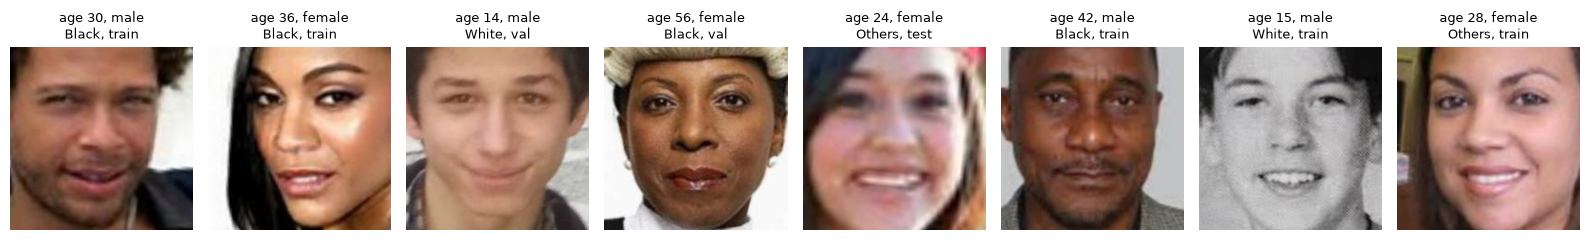

In [4]:
from concurrent.futures import ThreadPoolExecutor

from PIL import Image
import matplotlib.pyplot as plt

IMG_SIZE = 200
CACHE_NPY = CACHE_DIR / f"utkface_{IMG_SIZE}_uint8.npy"
CACHE_FILES = CACHE_DIR / f"utkface_{IMG_SIZE}_files.csv"   # row order of the cache

def load_chw(file: str) -> np.ndarray:
    """JPEG -> uint8 array (3, 200, 200)."""
    with Image.open(IMG_DIR / file) as im:
        a = np.asarray(im.convert("RGB"))                          # (H, W, C)
    assert a.shape == (IMG_SIZE, IMG_SIZE, 3), f"{file}: {a.shape}"
    return a.transpose(2, 0, 1)                                    # (C, H, W)

if not CACHE_NPY.exists():
    with track("prep_cache_200", kind="prep", gpu_ids=[0], notes="decode all JPEGs once into uint8 (N,3,200,200)") as info:
        t0 = time.time()
        out = np.lib.format.open_memmap(CACHE_NPY, mode="w+", dtype=np.uint8,
                                        shape=(len(split_df), 3, IMG_SIZE, IMG_SIZE))
        with ThreadPoolExecutor(max_workers=16) as pool:           # PIL releases the GIL while decoding
            for i, arr in enumerate(pool.map(load_chw, split_df.file, chunksize=64)):
                out[i] = arr
        out.flush(); del out
        split_df[["file"]].to_csv(CACHE_FILES, index=False)
        info["n_images"] = len(split_df); info["seconds"] = round(time.time() - t0, 1)
else:
    print(f"cache exists, not rebuilt: {CACHE_NPY.name}")

# --- load (memory-mapped) and check ---
images = np.load(CACHE_NPY, mmap_mode="r")
assert (pd.read_csv(CACHE_FILES).file.values == split_df.file.values).all(), "cache rows != split rows"
print(f"images: shape {images.shape}, dtype {images.dtype}, {images.nbytes / 1e9:.2f} GB on disk")

check = np.random.default_rng(SEED).choice(len(split_df), 8, replace=False)
for i in check:
    assert np.array_equal(images[i], load_chw(split_df.file[i])), f"row {i} differs from its JPEG"
print("8 random rows are identical to a fresh decode of their JPEG")

fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, i in zip(axes, check):
    r = split_df.iloc[i]
    ax.imshow(images[i].transpose(1, 2, 0))                       # back to (H, W, C) for plotting
    ax.set_title(f"age {r.age}, {GENDER[r.gender]}\n{RACE[r.race]}, {r.split}", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

## 5 · Standard models with a regression head

Both models are loaded with **ImageNet weights** (transfer learning) and only their **last layer** is replaced: ImageNet has 1000 classes, we predict **one number** (age).

| model | weights (decided) | ImageNet top-1 | original last layer | new last layer |
|---|---|---|---|---|
| ResNet18 | `IMAGENET1K_V1` | 69.76 % | `fc = Linear(512, 1000)` | `fc = Linear(512, 1)` |
| MobileNetV3-Large | `IMAGENET1K_V1` | 74.04 % | `classifier[3] = Linear(1280, 1000)` | `classifier[3] = Linear(1280, 1)` |

**Parameter counts by hand** (Linear: `in × out + out` for the bias):
- ResNet18: 11,689,512 − (512·1000 + 1000) + (512·1 + 1) = 11,689,512 − 513,000 + 513 = **11,177,025**
- MobileNetV3-L: 5,483,032 − (1280·1000 + 1000) + (1280·1 + 1) = 5,483,032 − 1,281,000 + 1,281 = **4,203,313**

The new layer starts with random weights; everything before it keeps the ImageNet weights.

**Input preprocessing (`to_input`)**, done on the GPU per batch from the `uint8` cache:
`x = (pixel / 255 − mean) / std` with the ImageNet `mean = (0.485, 0.456, 0.406)`, `std = (0.229, 0.224, 0.225)`, the scale the pretrained weights were trained on. No resize/crop (200 px).

The test at the end pushes 4 cached images through each model on `cuda:0` and checks that the output has shape `(4, 1)`, one predicted age per image. The predictions are meaningless for now (the head is untrained). This forward pass is logged as a `test` run.

In [5]:
import torch.nn as nn
import torchvision
from torchinfo import summary
import sys
sys.path.insert(0, str(REPO / "src"))          # so `models/own_cnn.py` can be imported
from models.own_cnn import OwnCNN               # our own CNN (section 15)

IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def to_input(batch_uint8: np.ndarray, device: str) -> torch.Tensor:
    """uint8 (B, 3, 200, 200) from the cache -> normalised float32 on the device."""
    # np.array(...) copies the batch out of the read-only memory-mapped cache (torch needs a writable array)
    x = torch.from_numpy(np.array(batch_uint8)).to(device).float().div_(255)
    return (x - IMAGENET_MEAN.to(device)) / IMAGENET_STD.to(device)

def build_model(name: str, pretrained: bool = True) -> nn.Module:
    if name == "resnet18":
        m = torchvision.models.resnet18(weights="IMAGENET1K_V1" if pretrained else None)
        print("  original head:", m.fc)
        m.fc = nn.Linear(m.fc.in_features, 1)                         # 512 -> 1
        print("  new head     :", m.fc)
    elif name == "mobilenet_v3_large":
        m = torchvision.models.mobilenet_v3_large(weights="IMAGENET1K_V1" if pretrained else None)
        print("  original head:", m.classifier[3])
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, 1)   # 1280 -> 1
        print("  new head     :", m.classifier[3])
    elif name == "own_cnn":                       # our own CNN, residual basic blocks, random init (section 15)
        m = OwnCNN(block="basic")
    elif name == "own_cnn_bottleneck":            # ablation: the same network with bottleneck blocks
        m = OwnCNN(block="bottleneck")
    else:
        raise ValueError(name)
    return m

def n_params(m: nn.Module) -> int:
    return sum(p.numel() for p in m.parameters())

# demo below runs only once (it is a logged run); delete its row in logs/runs.csv to repeat it
if not already_logged("test_heads_forward"):
    x = to_input(images[:4], "cuda:0")
    print(f"input batch: {tuple(x.shape)} {x.dtype}, mean {x.mean():.3f}, std {x.std():.3f}\n")

    with track("test_heads_forward", kind="test", gpu_ids=[0], notes="forward 4 images through both models, shape check") as info:
        for name in ("resnet18", "mobilenet_v3_large"):
            print(name)
            model = build_model(name).to("cuda:0").eval()
            with torch.no_grad():
                y = model(x)
            assert y.shape == (4, 1)
            print(f"  params: {n_params(model):,} | output shape {tuple(y.shape)} | untrained predictions {y.squeeze(1).tolist()}\n")
            info[f"params_{name}"] = n_params(model)

    print(summary(build_model("resnet18", pretrained=False), input_size=(1, 3, 200, 200), depth=1,
                  col_names=("output_size", "num_params", "mult_adds"), verbose=0))
else:
    print("demo 'test_heads_forward' already ran and is logged - skipped")

demo 'test_heads_forward' already ran and is logged - skipped


## 6 · Shared evaluation + the mean / median baseline

**One `evaluate()` for every model**, so all numbers in the results table are computed the same way (assignment 3.3: "same evaluation code for all models"). With $y_i$ = true age, $\hat y_i$ = prediction, $n$ images:

| metric | formula | meaning |
|---|---|---|
| MAE | $\frac{1}{n}\sum \lvert y_i-\hat y_i\rvert$ | average error in **years**; the main metric |
| RMSE | $\sqrt{\frac{1}{n}\sum (y_i-\hat y_i)^2}$ | also years, but large errors count more (squared) |
| R² | $1-\frac{\sum (y_i-\hat y_i)^2}{\sum (y_i-\bar y)^2}$ | share of the age variance explained; **0 = no better than predicting the mean**, 1 = perfect |

Plus **MAE per group** (gender, race, age band), required because UTKFace contains faces with group labels.

**Baseline (assignment 3.1):** ignore the image and always predict one number computed on **train** only:
- mean of train ages → minimises the squared error (best constant for RMSE)
- median of train ages → minimises the absolute error (best constant for MAE)

The baseline is a final "model" with nothing to tune, so it is evaluated on **val and test now**. Its test MAE is $\text{MAE}_\text{mean}$ in the acceptability rule, so it also gives us the first target:
$\text{MAE}_\text{own} \le 0.6 \times \text{MAE}_\text{mean}$.

Results go to `results/results.csv` (one row per model, the columns of the table in assignment 3.5) and the per-group errors to `results/per_group/`. The run is measured (`kind="eval"`).

In [6]:
RESULTS_CSV = REPO / "results" / "results.csv"
GROUP_DIR = REPO / "results" / "per_group"
GROUP_DIR.mkdir(parents=True, exist_ok=True)
AGE_BANDS = ["0-2", "3-12", "13-19", "20-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]

def evaluate(y_true, y_pred, meta: pd.DataFrame | None = None) -> tuple[dict, pd.DataFrame | None]:
    """Shared metrics for every model. meta: rows of split_df in the same order (for per-group MAE)."""
    y, p = np.asarray(y_true, dtype=np.float64), np.asarray(y_pred, dtype=np.float64)
    err = p - y
    metrics = {"mae": np.abs(err).mean(),
               "rmse": np.sqrt((err ** 2).mean()),
               "r2": 1 - (err ** 2).sum() / ((y - y.mean()) ** 2).sum(),
               "n": len(y)}
    groups = None
    if meta is not None:
        m = meta.assign(abs_err=np.abs(err), gender=meta.gender.map(GENDER), race=meta.race.map(RACE))
        groups = pd.concat([m.groupby(col).abs_err.agg(mae="mean", n="size").assign(group=col)
                            for col in ("gender", "race", "age_band")])
        groups = groups.rename_axis("value").reset_index()[["group", "value", "n", "mae"]]
        order = list(GENDER.values()) + list(RACE.values()) + AGE_BANDS          # natural order, not alphabetical
        groups = groups.sort_values("value", key=lambda s: s.map(order.index), kind="stable")
    return metrics, groups

def save_result(row: dict) -> None:
    """One row per model in results/results.csv (re-running a model replaces its row)."""
    log = pd.read_csv(RESULTS_CSV) if RESULTS_CSV.exists() else pd.DataFrame()
    if len(log):
        log = log[log.model != row["model"]]
    pd.concat([log, pd.DataFrame([row])], ignore_index=True).to_csv(RESULTS_CSV, index=False)

train = split_df[split_df.split == "train"]
val   = split_df[split_df.split == "val"].reset_index(drop=True)
test  = split_df[split_df.split == "test"].reset_index(drop=True)

# the baseline evaluation runs only once (it is a logged run that uses the test set)
if not already_logged("eval_baseline_mean_median"):
    with track("eval_baseline_mean_median", kind="eval", gpu_ids=[0], notes="constant predictors from train stats") as info:
        rows = []
        for name, const in (("mean", train.age.mean()), ("median", train.age.median())):
            for split_name, part in (("val", val), ("test", test)):
                m, g = evaluate(part.age, np.full(len(part), const), part)
                rows.append({"baseline": name, "constant": round(const, 3), "split": split_name,
                             **{k: round(v, 3) for k, v in m.items() if k != "n"}, "n": m["n"]})
                if split_name == "test":
                    g.to_csv(GROUP_DIR / f"baseline_{name}_test.csv", index=False)
                    info[f"{name}_test_mae"] = round(m["mae"], 4)
        table = pd.DataFrame(rows)

    print(table.to_string(index=False))

    mae_mean = table.query("baseline == 'mean' and split == 'test'").mae.item()
    print(f"\nMAE_mean (test)          = {mae_mean:.3f} years")
    print(f"target 0.6 × MAE_mean    = {0.6 * mae_mean:.3f} years  <- own CNN must be at or below this (and ≤ 1.15 × MAE_best)")

    for name in ("mean", "median"):
        r = table.query("baseline == @name and split == 'test'").iloc[0]
        save_result({"model": f"{name} baseline", "machine": MACHINE, "params": 0, "mflops_per_img": 0,
                     "test_mae": r.mae, "test_rmse": r.rmse, "test_r2": r.r2,
                     "train_kwh": 0, "train_kg_co2": 0, "project_kg_co2": None, "ms_per_img": 0})

    print("\nper-group test MAE of the mean baseline:")
    g = pd.read_csv(GROUP_DIR / "baseline_mean_test.csv")
    with pd.option_context("display.width", 200):
        for col in ("gender", "race", "age_band"):
            t = g[g.group == col].set_index("value")[["n", "mae"]].T
            print(t.apply(lambda r: r.map("{:.0f}".format if r.name == "n" else "{:.2f}".format), axis=1).to_string(), "\n")
else:
    print("baseline already evaluated and logged - see results/results.csv")

baseline already evaluated and logged - see results/results.csv


## 7 · Training data on the GPU + augmentation

**Decisions (user, 2026-11-18):** fine-tuning option **A** (head first, then only the last layers; early layers stay frozen), **L1 loss**, augmentation **flip + shift + greyscale**, max 15 epochs with early stopping (patience 3), bf16 mixed precision.

**Data on the GPU.** Train + val as `uint8` = (16,131 + 3,461) × 120,000 B = **2.35 GB**, which fits easily in the 32 GB of the RTX 5090. We copy it **once**; afterwards every batch is just an index into GPU memory: no DataLoader workers, no JPEG decoding, no CPU→GPU copy per batch. That keeps the CPU (and its energy) almost idle during training.

**Batch pipeline** `make_batch(X, idx, train)`:
1. `uint8 → float / 255` → values in [0, 1]
2. **train only**, each image independently:
   - **horizontal flip**, p = 0.5: a face mirrored left↔right is still the same age
   - **rotation** by a random angle `a ∈ [−10°, +10°]` and **shift** by `dx, dy ∈ [−8, 8]` pixels, both in **one** affine transform (so the image is interpolated only once, bilinear). Teaches the model that small head tilts and the exact face position do not matter (UTKFace faces are aligned, but not perfectly).
     Empty corners/borders are filled with **black (zeros)**, not with a mirror image: reflection would create fake face content (a second ear, mirrored hair) that the model could treat as a real feature; black carries no face information (decision: user).
   - **greyscale**, p = 0.1: `Y = 0.299 R + 0.587 G + 0.114 B` (ITU-R 601 luma, same as PIL / torchvision), copied to all 3 channels. The EDA found 868 b&w photos (3.66 %), rare among children and some groups, so the model could learn "b&w → old"; showing colour photos in b&w breaks that shortcut
3. ImageNet normalisation `(x − mean) / std`

Val and test images are **never** augmented. The figure shows the same 8 training faces: original (top), one random augmentation (middle), and, only to show that it works, the same augmentation with greyscale forced to p = 1 (bottom; training uses p = 0.1).

In [7]:
import torch.nn.functional as F

DEV = "cuda:0"                                  # GPU 1 is used by another user (Ollama)
tr_idx = np.flatnonzero(split_df.split.values == "train")
va_idx = np.flatnonzero(split_df.split.values == "val")

X_train = torch.from_numpy(np.array(images[tr_idx])).to(DEV)          # uint8 (16131, 3, 200, 200)
X_val   = torch.from_numpy(np.array(images[va_idx])).to(DEV)          # uint8 ( 3461, 3, 200, 200)
y_train = torch.tensor(split_df.age.values[tr_idx], dtype=torch.float32, device=DEV)
y_val   = torch.tensor(split_df.age.values[va_idx], dtype=torch.float32, device=DEV)
MEAN_D, STD_D = IMAGENET_MEAN.to(DEV), IMAGENET_STD.to(DEV)
LUMA = torch.tensor([0.299, 0.587, 0.114], device=DEV).view(1, 3, 1, 1)

def augment(x: torch.Tensor, max_shift: int = 8, max_deg: float = 10.0, p_grey: float = 0.1,
            gen: torch.Generator | None = None) -> torch.Tensor:
    """x: float (B, 3, H, W) in [0, 1]. Per image: random flip, rotation + shift, greyscale."""
    B, _, H, W = x.shape
    r = lambda *s: torch.rand(*s, device=x.device, generator=gen)
    flip = r(B) < 0.5
    x = torch.where(flip.view(B, 1, 1, 1), x.flip(3), x)
    # rotation + shift in ONE affine matrix  theta = [[cos a, -sin a, tx], [sin a, cos a, ty]]
    # grid_sample uses coordinates in [-1, 1], so 1 pixel = 2/W  ->  tx = 2*dx/W
    a = (r(B) * 2 - 1) * max_deg * torch.pi / 180                       # radians in [-10°, +10°]
    d = torch.floor(r(B, 2) * (2 * max_shift + 1)) - max_shift          # integers in [-8, 8]
    theta = torch.stack([torch.stack([a.cos(), -a.sin(), 2 * d[:, 0] / W], 1),
                         torch.stack([a.sin(),  a.cos(), 2 * d[:, 1] / H], 1)], 1)   # (B, 2, 3)
    grid = F.affine_grid(theta, x.shape, align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    grey = r(B) < p_grey
    y = (x * LUMA).sum(1, keepdim=True).expand(-1, 3, -1, -1)
    return torch.where(grey.view(B, 1, 1, 1), y, x)

def make_batch(X: torch.Tensor, idx: torch.Tensor, train: bool) -> torch.Tensor:
    x = X[idx].float().div_(255)
    if train:
        x = augment(x)
    return (x - MEAN_D) / STD_D

print(f"on {DEV}: X_train {tuple(X_train.shape)} {X_train.dtype}, X_val {tuple(X_val.shape)}  "
      f"-> {(X_train.nbytes + X_val.nbytes) / 1e9:.2f} GB")
print(f"y_train: mean {y_train.mean():.3f} (= mean baseline constant), min {y_train.min():.0f}, max {y_train.max():.0f}")

# demo below runs only once (it is a logged run); delete its row in logs/runs.csv to repeat it
if not already_logged("test_augment_demo"):
    # --- show 8 training images: original / augmented / augmented with greyscale forced (demo only) ---
    with track("test_augment_demo", kind="test", gpu_ids=[0], notes="copy train/val to GPU, show augmented images (rotation + zeros)"):
        idx = torch.arange(8, device=DEV) * 2000
        x01 = X_train[idx].float() / 255
        rows = [x01,
                augment(x01, gen=torch.Generator(DEV).manual_seed(SEED)),
                augment(x01, p_grey=1.0, gen=torch.Generator(DEV).manual_seed(SEED))]   # same flips/angles/shifts
    fig, axes = plt.subplots(3, 8, figsize=(16, 6.4))
    for i, (row, label) in enumerate(zip(rows, ["original", "augmented", "grey forced\n(demo)"])):
        for j in range(8):
            axes[i, j].imshow(row[j].permute(1, 2, 0).cpu()); axes[i, j].axis("off")
        axes[i, 0].text(-30, 100, label, rotation=90, va="center", ha="center")
    for j in range(8):
        axes[0, j].set_title(f"age {y_train[idx[j]]:.0f}", fontsize=9)
    plt.tight_layout(); plt.show()
else:
    print("demo 'test_augment_demo' already ran and is logged - skipped")

on cuda:0: X_train (16131, 3, 200, 200) torch.uint8, X_val (3461, 3, 200, 200)  -> 2.35 GB
y_train: mean 33.228 (= mean baseline constant), min 1, max 116
demo 'test_augment_demo' already ran and is logged - skipped


## 8 · Freezing plan (option A): what trains in each phase

**Rule:** unfreeze only the layers that work on the **small, deep feature maps (13×13 and 7×7)**. They hold ImageNet-specific features (objects) that must adapt to age. The early layers (100×100 → 25×25) hold generic edges and textures and stay frozen with their ImageNet weights.

| phase | ResNet18 trains | MobileNetV3-L trains | epochs |
|---|---|---|---|
| **1 · head** | `fc` (new, 513 params) | `classifier[3]` (new, 1,281 params) | 1 |
| **2 · last layers** | `layer3`, `layer4`, `fc` | `features[7:]` (blocks at 13×13 and 7×7), `classifier` | ≤ 14, early stopping |

`set_phase()` does two things:
1. `requires_grad = False` for every frozen parameter, so the optimizer cannot change it and no weight gradient is computed.
2. **BatchNorm in frozen layers stays in `eval()` mode.** In `train()` mode BN would keep updating its running mean/variance with our faces even though its weights are frozen, which silently changes the "frozen" layers.

**Why this saves energy.** One training step = forward pass (F) + backward pass. Backward through a layer costs about 2× its forward (gradient w.r.t. the input and w.r.t. the weights). A frozen layer **before** all trainable layers needs **no backward at all**. So, as an estimate,

$$\text{step cost} \approx F_\text{all} + 2\,F_\text{trainable} \qquad \text{vs. full fine-tuning} \approx 3\,F_\text{all}$$

MACs are counted with a hook on every `Conv2d` and `Linear`: conv MACs = output elements × (C_in / groups) × k × k; Linear MACs = in × out (BatchNorm / activations not counted, the usual convention).

In [8]:
TRAIN_PARTS = {   # module-name prefixes that are trainable in each phase
    "resnet18":           {"head": ["fc"],
                           "last": ["layer3", "layer4", "fc"],
                           "full": ["conv1", "bn1", "layer1", "layer2", "layer3", "layer4", "fc"]},   # everything
    "mobilenet_v3_large": {"head": ["classifier.3"],
                           "last": [f"features.{i}" for i in range(7, 17)] + ["classifier"],
                           "full": ["features", "classifier"]},                                        # everything
    # own CNN (section 15): trained from scratch, so only "full" (every layer) exists
    "own_cnn":            {"full": ["stem", "stage1", "stage2", "stage3", "stage4", "fc"]},
    "own_cnn_bottleneck": {"full": ["stem", "stage1", "stage2", "stage3", "stage4", "fc"]},
}

def _in_parts(name: str, parts: list[str]) -> bool:
    return any(name == p or name.startswith(p + ".") for p in parts)

def set_phase(model: nn.Module, name: str, phase: str) -> list[nn.Parameter]:
    """Freeze everything except TRAIN_PARTS[name][phase]; returns the trainable parameters."""
    parts = TRAIN_PARTS[name][phase]
    for n, p in model.named_parameters():
        p.requires_grad = _in_parts(n, parts)
    return [p for p in model.parameters() if p.requires_grad]

def set_train_mode(model: nn.Module, name: str, phase: str) -> None:
    """model.train() only for the trainable parts; frozen parts (incl. their BatchNorm) stay in eval()."""
    model.eval()
    for n, m in model.named_modules():
        if n and _in_parts(n, TRAIN_PARTS[name][phase]):
            m.train()

def macs_per_module(model: nn.Module, size: int = 200) -> dict[str, int]:
    """Forward MACs of every Conv2d / Linear, by module name (one image)."""
    macs, hooks = {}, []
    for n, m in model.named_modules():
        if isinstance(m, nn.Conv2d):
            hooks.append(m.register_forward_hook(lambda mod, i, o, n=n:
                macs.__setitem__(n, o.numel() * (mod.in_channels // mod.groups) * mod.kernel_size[0] * mod.kernel_size[1])))
        elif isinstance(m, nn.Linear):
            hooks.append(m.register_forward_hook(lambda mod, i, o, n=n: macs.__setitem__(n, mod.in_features * mod.out_features)))
    with torch.no_grad():
        model.eval()(torch.zeros(1, 3, size, size))
    for h in hooks:
        h.remove()
    return macs

# demo below runs only once (it is a logged run); delete its row in logs/runs.csv to repeat it
if not already_logged("test_freezing_plan"):
    rows = []
    with track("test_freezing_plan", kind="test", gpu_ids=[0], notes="count params/MACs per phase, CPU only"):
        for name in ("resnet18", "mobilenet_v3_large"):
            model = build_model(name)
            macs = macs_per_module(model)
            F_all = sum(macs.values())
            total = n_params(model)
            for phase in ("head", "last"):
                trainable = sum(p.numel() for p in set_phase(model, name, phase))
                set_train_mode(model, name, phase)
                F_t = sum(v for n, v in macs.items() if _in_parts(n, TRAIN_PARTS[name][phase]))
                bn = [m for m in model.modules() if isinstance(m, nn.BatchNorm2d)]
                rows.append({"model": name, "phase": phase,
                             "trainable params": f"{trainable:,}", "frozen params": f"{total - trainable:,}",
                             "fwd GMACs": round(F_all / 1e9, 3), "trainable GMACs": round(F_t / 1e9, 3),
                             "step cost vs full FT": f"{(F_all + 2 * F_t) / (3 * F_all):.0%}",
                             "BN train/eval": f"{sum(m.training for m in bn)}/{sum(not m.training for m in bn)}"})

    print()
    with pd.option_context("display.width", 200, "display.max_columns", 20):
        print(pd.DataFrame(rows).to_string(index=False))

    # where the 13x13 boundary is in MobileNetV3-L (check that features[7] is the first 13x13 block)
    m = build_model("mobilenet_v3_large"); x = torch.zeros(1, 3, 200, 200); shapes = []
    with torch.no_grad():
        for i, blk in enumerate(m.features):
            x = blk(x); shapes.append(f"{i}:{x.shape[-1]}")
    print("\nMobileNetV3-L feature map size after each block (index:size):", " ".join(shapes))
else:
    print("demo 'test_freezing_plan' already ran and is logged - skipped")

demo 'test_freezing_plan' already ran and is logged - skipped


## 9 · The training loop (definitions only; nothing runs here)

`train_model(name, run_name, strategy, ...)` trains one standard model with strategy **A** (head first, then last layers) or **full** (every layer from epoch 1) and returns the **best** model (lowest val MAE) and its history. The whole run is inside `track(...)`, so its energy is logged even if it crashes.

| setting | value | why |
|---|---|---|
| loss | **L1** = mean \|ŷ − y\| | = the reported metric (MAE); robust to wrong labels (user decision) |
| head init | weights = **0**, bias = **33.23** (train mean) | the model starts exactly as the mean baseline (MAE ≈ 15.4) instead of predicting ≈ 0 (MAE ≈ 33). *run01 used random weights → start loss ≈ 18.8* |
| phase 1 | **1 epoch**, head only, AdamW lr **1e-3** | the random head learns first; the frozen backbone gets no gradient |
| phase 2 | layers at 13×13 / 7×7 + head, AdamW lr **1e-4** (backbone) / **1e-3** (head) | pretrained weights only need small changes → 10× smaller lr than the new head |
| lr schedule (phase 2) | **cosine** from the lr above to 0 over the remaining 14 epochs | big steps first, fine steps at the end |
| weight decay | **0.01** (AdamW default) | mild regularisation |
| batch size | **128**, full batches only | 16,131 // 128 = **126** steps per epoch; the 3 leftover images are skipped (a new random 3 each epoch). *run01 had a 3-image last batch → loss spikes at every epoch end* |
| precision | **bf16 autocast** (the RTX 5090 has native bf16) | ~2× faster matmuls, less memory traffic → less energy; bf16 has the same range as float32, so no loss scaling is needed |
| stopping | exactly **15** epochs, **no early stopping** (`patience=None`), keep the best val epoch | the cosine lr always reaches 0 and every run gets the same budget. *run01 used patience 3: ResNet18 stopped at epoch 10 while the lr was still 3.9e-4* |
| evaluation | val MAE after every epoch, no augmentation | val decides everything; **test is never touched here** |

`torch.backends.cudnn.benchmark = True` lets cuDNN pick the fastest convolution algorithm once (faster → less energy). Cost: results are reproducible only up to tiny floating-point differences, not bit-for-bit.

Code layout (read top to bottom): `make_optimizer` (freeze + AdamW with 2 learning rates) → `train_one_epoch` (the 4 steps of one batch) → `predict` / `val_mae` → `train_model` (phase 1 loop, phase 2 loop with early stopping, save the best).

Outputs per run: `logs/train/<run>.csv` (one row per epoch: phase, train L1, val MAE, lr, seconds), `logs/train/<run>_steps.csv` (loss of every batch), a figure `results/figures/train_<run>.png` (loss per step on a linear and a log axis with val MAE per epoch, and seconds per epoch), best weights in `checkpoints/<run>.pt` (gitignored), one row in `logs/runs.csv` + `emissions.csv`.

In [9]:
import copy   # copy.deepcopy: make a full, independent copy of the weights
import math   # math.inf (infinity), math.ceil (round up)
import matplotlib.pyplot as plt

TRAIN_LOG_DIR = REPO / "logs" / "train"      # one CSV per run: a row per epoch
CKPT_DIR = REPO / "checkpoints"              # saved weights (.pt files, not in git)
FIG_DIR = REPO / "results" / "figures"       # training plots
TRAIN_LOG_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)

# cuDNN (NVIDIA's convolution library) tries several algorithms once and keeps the fastest
torch.backends.cudnn.benchmark = True


# ---------------------------------------------------------------------------
# Small helpers
# ---------------------------------------------------------------------------

def get_head(model, name):
    """Return the new 1-output Linear layer (the 'head') of the model."""
    if name in ("resnet18", "own_cnn", "own_cnn_bottleneck"):
        return model.fc                # ResNet18 and our own CNN: the last layer is the attribute `fc`
    # MobileNetV3: `classifier` is a Sequential (a list of layers):
    #   (0) Linear 960->1280, (1) Hardswish, (2) Dropout, (3) Linear 1280->1  <- position 3 = our head
    return model.classifier[3]


def make_optimizer(model, name, phase, lr_head, lr_backbone, weight_decay):
    """Freeze/unfreeze the layers for this phase, then create the AdamW optimizer.
    Two learning rates: the new head learns fast (lr_head),
    the pretrained layers learn slowly (lr_backbone) so their ImageNet knowledge is not destroyed."""
    set_phase(model, name, phase)      # from step 8: requires_grad True only for this phase's layers

    head_params = list(get_head(model, name).parameters())       # head weight + bias
    head_ids = {id(p) for p in head_params}                       # id() = unique number of each tensor
    backbone_params = [p for p in model.parameters()
                       if p.requires_grad and id(p) not in head_ids]   # trainable, but not the head

    groups = [{"params": head_params, "lr": lr_head}]
    if backbone_params:                # empty in the "head" phase (everything else is frozen)
        groups.append({"params": backbone_params, "lr": lr_backbone})
    # AdamW = Adam + weight decay (pulls weights slightly towards 0 every step, mild regularisation)
    return torch.optim.AdamW(groups, weight_decay=weight_decay)


def train_one_epoch(model, name, phase, optimizer, scheduler, X, y, batch_size, gen, w=None):
    # only FULL batches: 16,131 // 128 = 126 batches; the 3 leftover images are skipped this epoch
    # (a 3-image batch gives a very noisy full-size update; the shuffle changes which 3 every epoch)
    """One pass over all training images.
    Returns (mean L1 loss in years, list with the loss of every step) - the list is for the plots."""
    set_train_mode(model, name, phase)     # from step 8: train() only for trainable layers
    # gen = our own random-number generator (fixed seed): same seed -> same "random" order every run
    order = torch.randperm(len(X), generator=gen, device=DEV)   # a shuffled list of 0..N-1
    total_loss = 0.0
    step_losses = []                                 # loss of each batch, for the step plot

    n_full = (len(X) // batch_size) * batch_size     # 126 * 128 = 16,128
    for start in range(0, n_full, batch_size):       # start = 0, 128, 256, ...
        idx = order[start:start + batch_size]        # indices of the images in this batch

        # 1. batch: uint8 -> [0, 1] -> augment -> ImageNet normalisation
        x = X[idx].float() / 255
        x = augment(x, gen=gen)                      # flips/angles/shifts also drawn from gen
        x = (x - MEAN_D) / STD_D

        # 2. forward pass; autocast = do the heavy maths in bfloat16 (faster, less energy)
        with torch.autocast("cuda", dtype=torch.bfloat16):
            pred = model(x)                          # shape (B, 1): one number per image
        pred = pred.float().squeeze(1)               # back to float32; squeeze: (B, 1) -> (B,)

        # 3. L1 loss = mean |predicted age - true age| over the batch
        if w is None:
            loss = F.l1_loss(pred, y[idx])
        else:
            # weighted L1 (section 14): each image's error counts w times; dividing by the sum of the
            # weights makes it a weighted AVERAGE, so the loss stays in "years" and the lr keeps its meaning
            loss = (w[idx] * (pred - y[idx]).abs()).sum() / w[idx].sum()

        # 4. backward pass and weight update
        optimizer.zero_grad()      # clear the gradients of the previous batch (PyTorch adds them up otherwise)
        loss.backward()            # compute d(loss)/d(weight) for every trainable weight
        optimizer.step()           # change each trainable weight a little against its gradient
        if scheduler is not None:
            scheduler.step()       # lower the learning rate a little (cosine curve, phase 2 only)

        step_losses.append(loss.item())              # .item(): tensor -> plain Python number
        total_loss += step_losses[-1] * len(idx)

    return total_loss / n_full, step_losses


@torch.no_grad()       # no gradients needed when only predicting: saves memory and time
def predict(model, X, batch_size=512):
    """Predicted ages for all images in X (no augmentation)."""
    model.eval()       # eval mode: BatchNorm uses its stored statistics, Dropout is off
    preds = []
    for start in range(0, len(X), batch_size):
        idx = torch.arange(start, min(start + batch_size, len(X)), device=DEV)   # images in order
        x = make_batch(X, idx, train=False)          # train=False -> no augmentation
        with torch.autocast("cuda", dtype=torch.bfloat16):
            preds.append(model(x).float().squeeze(1))
    return torch.cat(preds)                          # join the batches into one long tensor


def val_mae(model, X, y):
    """Mean absolute error in years on the given (validation) images."""
    return (predict(model, X) - y).abs().mean().item()


def plot_training(run_name, history, steps):
    """3 panels: loss per step (linear y), the same with log y, time per epoch.
    history: one row per epoch (val MAE), steps: one row per batch (train L1)."""
    h, s = pd.DataFrame(history), pd.DataFrame(steps)
    smooth = s.loss.rolling(20, min_periods=1).mean()           # moving average over 20 steps
    epoch_end_step = s.groupby("epoch").step.max()              # step number where each epoch ends

    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    for ax, log in zip(axes[:2], (False, True)):
        ax.plot(s.step, s.loss, color="tab:blue", alpha=0.25, lw=0.8, label="train L1 (each step)")
        ax.plot(s.step, smooth, color="tab:blue", lw=2, label="train L1 (20-step average)")
        ax.plot(epoch_end_step.values, h.val_mae, "o-", color="tab:red", lw=2, label="val MAE (end of epoch)")
        for e, st in epoch_end_step.items():                    # dotted line at every epoch boundary
            ax.axvline(st, color="grey", ls=":", lw=0.8)
        if (s.phase == "head").any():                           # strategy A: mark phase 1 -> phase 2
            head_end = s[s.phase == "head"].step.max()
            ax.axvline(head_end, color="black", lw=1.2)
            ax.text(head_end, 0.98, " phase 2 ->", transform=ax.get_xaxis_transform(), va="top", fontsize=8)
        ax.set_xlabel("training step (batch)"); ax.set_ylabel("years")
        if log:
            ax.set_yscale("log"); ax.set_title(f"{run_name}: loss, log scale")
            lo, hi = ax.get_ylim()                              # plain numbers instead of 6x10^0
            ax.set_yticks([t for t in (1, 2, 3, 4, 5, 6, 8, 10, 15, 20, 30, 40) if lo <= t <= hi])
            ax.yaxis.set_major_formatter(plt.ScalarFormatter()); ax.yaxis.set_minor_formatter(plt.NullFormatter())
        else:
            ax.set_title(f"{run_name}: loss"); ax.legend(fontsize=8)

    ax = axes[2]
    ax.bar(h.epoch, h.seconds, color=["tab:orange" if p == "head" else "tab:green" for p in h.phase])
    ax2 = ax.twinx()                                            # second y-axis for the running total
    ax2.plot(h.epoch, h.seconds.cumsum(), "k.-", label="cumulative")
    ax.set_xlabel("epoch  (orange = phase 1 head, green = phase 2 / full)"); ax.set_ylabel("seconds per epoch")
    ax2.set_ylabel("cumulative seconds")
    ax.set_xticks(h.epoch)                                      # whole epoch numbers only
    ax.set_title(f"time: {h.seconds.sum():.1f} s in {len(h)} epochs")
    plt.tight_layout()
    fig.savefig(FIG_DIR / f"train_{run_name}.png", dpi=110)
    plt.show()


# ---------------------------------------------------------------------------
# Main function: option A = phase 1 (head only), then phase 2 (last layers)
# ---------------------------------------------------------------------------

def train_model(name, run_name, strategy="A", kind="train", n_train=None, n_val=None,
                head_epochs=1, max_epochs=15, patience=None, batch_size=128,
                lr_head=1e-3, lr_backbone=1e-4, weight_decay=0.01, sample_weights=None, warmup_epochs=0):
    """strategy "A":    phase 1 = head only for `head_epochs`, phase 2 = last layers + head.
       strategy "full": every layer trains from epoch 1 (no head phase).
       patience=None:   no early stopping, always `max_epochs` (cosine lr reaches 0); best val epoch is kept.
       sample_weights:  None = plain L1; else one weight per training image (weighted L1, section 14).
       warmup_epochs:   0 = plain cosine (standard models); k = lr rises linearly from ~0 to its start value
                        over the first k epochs, then cosine to 0 (own CNN from scratch, section 15).
       Own CNN: pass lr_head = lr_backbone = lr (one learning rate, nothing is pretrained)."""
    if strategy == "full":
        head_epochs = 0
    second_phase = "last" if strategy == "A" else "full"
    seed_everything(SEED)          # same start for every run (weights of the new head, etc.)
    # our own random-number generator on the GPU, seeded with 655: shuffling + augmentation use it,
    # so two runs with the same settings see exactly the same batches and augmentations
    gen = torch.Generator(DEV).manual_seed(SEED)

    # data (n_train / n_val: a small subset, only for the smoke test)
    Xtr, ytr, Xva, yva = X_train, y_train, X_val, y_val
    wtr = sample_weights                                  # None = every image counts the same
    if n_train is not None:
        pick = torch.randperm(len(Xtr), generator=gen, device=DEV)[:n_train]   # n_train random images
        Xtr, ytr = Xtr[pick], ytr[pick]
        wtr = None if wtr is None else wtr[pick]
    if n_val is not None:
        # random, NOT the first n_val rows: the split file is sorted by file name ("10_...", "100_...",
        # "11_..."), so the first rows are mostly teenagers and 100-year-olds (smoke test 1 had mean age 15.5)
        pick = torch.randperm(len(Xva), generator=gen, device=DEV)[:n_val]
        Xva, yva = Xva[pick], yva[pick]

    history = []                                         # one dict per epoch -> CSV at the end
    steps = []                                           # one dict per batch -> step plot + CSV
    run_start = time.time()

    def log_steps(epoch, phase, step_losses):
        """Append this epoch's step losses to `steps`, numbering steps across epochs."""
        for loss in step_losses:
            steps.append({"step": len(steps) + 1, "epoch": epoch, "phase": phase, "loss": loss})
    best_mae, best_epoch, best_weights = math.inf, 0, None   # inf: any real MAE is better

    def end_of_epoch(epoch, phase, train_loss, seconds, lr):
        """Evaluate on val, print + store the epoch, remember the best weights.
        Returns True if this epoch is the best so far."""
        nonlocal best_mae, best_epoch, best_weights     # change the variables of train_model
        mae = val_mae(model, Xva, yva)
        history.append({"epoch": epoch, "phase": phase, "train_l1": train_loss,
                        "val_mae": mae, "lr_head": lr, "seconds": seconds})
        print(f"epoch {epoch:2d} [{phase}]  train L1 {train_loss:6.3f}  |  val MAE {mae:6.3f}"
              f"  |  lr {lr:.1e}  |  {seconds:4.1f} s")
        if mae < best_mae:
            best_mae, best_epoch = mae, epoch
            # state_dict = all weights by name; deepcopy, otherwise later epochs would overwrite it
            best_weights = copy.deepcopy(model.state_dict())
            return True
        return False

    # everything inside `with track(...)` is measured by CodeCarbon (step 3)
    loss_name = "L1" if wtr is None else "weighted L1"
    with track(run_name, kind=kind, gpu_ids=[0], notes=f"{name}, strategy {strategy}, {loss_name}, bf16, batch {batch_size}, {max_epochs} ep") as info:
        model = build_model(name).to(DEV)          # step 5: ImageNet weights + new head, moved to the GPU
        with torch.no_grad():
            # head weights = 0 and bias = mean training age: before training the model predicts exactly
            # 33.23 for every face = the mean baseline (random weights would add a random offset)
            get_head(model, name).weight.zero_()
            if hasattr(model, "out_mean"):
                # own CNN: the head predicts the age in standard deviations, age = mean + std * head
                # (section 15.3.1); bias 0 -> the untrained model also predicts exactly the mean
                model.out_mean.fill_(y_train.mean().item())
                model.out_std.fill_(y_train.std().item())
                get_head(model, name).bias.zero_()
            else:
                get_head(model, name).bias.fill_(y_train.mean().item())

        # ---- phase 1: train only the new head (strategy A only) ------------------
        if head_epochs > 0:
            optimizer = make_optimizer(model, name, "head", lr_head, lr_backbone, weight_decay)
        for epoch in range(1, head_epochs + 1):
            t0 = time.time()
            loss, step_losses = train_one_epoch(model, name, "head", optimizer, None, Xtr, ytr, batch_size, gen, wtr)
            log_steps(epoch, "head", step_losses)
            end_of_epoch(epoch, "head", loss, time.time() - t0, lr_head)

        # ---- phase 2: "last" layers + head (A) or all layers ("full"), cosine lr ----
        optimizer = make_optimizer(model, name, second_phase, lr_head, lr_backbone, weight_decay)
        phase2_epochs = max_epochs - head_epochs                 # 14 for A, 15 for full
        steps_per_epoch = len(Xtr) // batch_size                 # 16,131 // 128 = 126 full batches
        # cosine: lr goes smoothly from its start value down to 0 over all phase-2 steps
        total_steps = phase2_epochs * steps_per_epoch
        if warmup_epochs == 0:
            scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=total_steps)
        else:
            warm = warmup_epochs * steps_per_epoch
            def lr_factor(step):       # multiplies the start lr of every parameter group
                if step < warm:
                    return (step + 1) / warm                                     # linear warm-up 1/warm ... 1
                return 0.5 * (1 + math.cos(math.pi * (step - warm) / (total_steps - warm)))   # cosine 1 -> 0
            scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)

        epochs_without_improvement = 0
        for epoch in range(head_epochs + 1, max_epochs + 1):
            t0 = time.time()
            lr_now = optimizer.param_groups[0]["lr"]               # current lr of the head
            loss, step_losses = train_one_epoch(model, name, second_phase, optimizer, scheduler, Xtr, ytr, batch_size, gen, wtr)
            log_steps(epoch, second_phase, step_losses)
            improved = end_of_epoch(epoch, second_phase, loss, time.time() - t0, lr_now)

            # early stopping (only if patience is set): stop after `patience` epochs without a better val MAE
            epochs_without_improvement = 0 if improved else epochs_without_improvement + 1
            if patience is not None and epochs_without_improvement == patience:
                print(f"early stop: val MAE did not improve for {patience} epochs")
                break

        # ---- keep the best epoch, save weights and log --------------------------
        model.load_state_dict(best_weights)                      # go back to the best epoch's weights
        torch.save(best_weights, CKPT_DIR / f"{run_name}.pt")    # weights file
        pd.DataFrame(history).to_csv(TRAIN_LOG_DIR / f"{run_name}.csv", index=False)
        pd.DataFrame(steps).to_csv(TRAIN_LOG_DIR / f"{run_name}_steps.csv", index=False)
        # `info` values end up as extra columns in logs/runs.csv
        info.update({"model": name, "strategy": strategy, "loss": loss_name, "best_val_mae": round(best_mae, 4), "best_epoch": best_epoch,
                     "epochs_run": len(history), "n_train": len(Xtr), "n_val": len(Xva)})

    print(f"best val MAE {best_mae:.3f} at epoch {best_epoch}  ->  checkpoints/{run_name}.pt"
          f"  |  total {time.time() - run_start:.1f} s")
    plot_training(run_name, history, steps)      # plotting is outside `track`: not part of training
    return model, pd.DataFrame(history)


print("defined: train_model(), predict(), val_mae(), plot_training()  - nothing trained")

defined: train_model(), predict(), val_mae(), plot_training()  - nothing trained


### 9.1 · Smoke test (only after the user's OK)

Before any real run, check that the loop works end to end on a **tiny subset**: 512 training images, 256 val images, 2 epochs (1 head + 1 last-layers), for both models. It is logged as `kind="test"`.

What to look for: no crash, val MAE goes **down** from about the mean-baseline level, the checkpoint and the log file are written. The numbers themselves mean nothing (far too little data).

--- resnet18 ---


  original head: Linear(in_features=512, out_features=1000, bias=True)
  new head     : Linear(in_features=512, out_features=1, bias=True)


epoch  1 [head]  train L1 15.726  |  val MAE 19.484  |  lr 1.0e-03  |   0.8 s


epoch  2 [last]  train L1 15.362  |  val MAE 18.154  |  lr 1.0e-03  |   0.6 s
[smoke_resnet18] ok | 1.7 s | 0.065 Wh (cpu 0.003, gpu 0.057, ram 0.005) | 0.030 g CO2eq
best val MAE 18.154 at epoch 2  ->  checkpoints/smoke_resnet18.pt  |  total 1.8 s


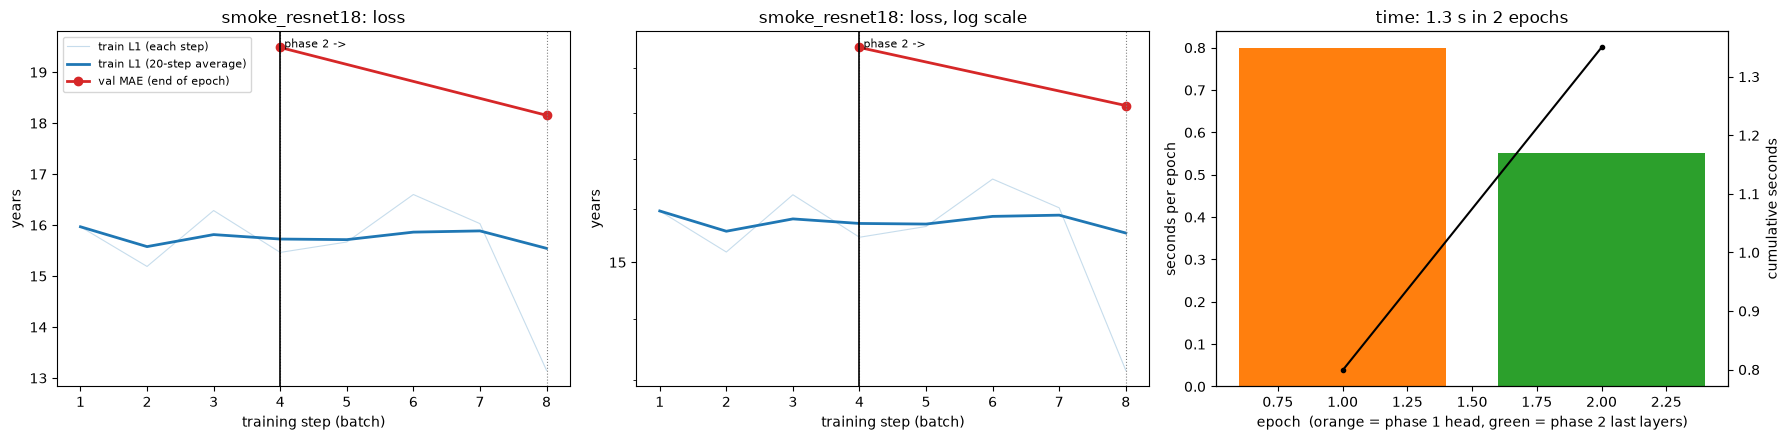

--- mobilenet_v3_large ---
  original head: Linear(in_features=1280, out_features=1000, bias=True)
  new head     : Linear(in_features=1280, out_features=1, bias=True)


epoch  1 [head]  train L1 15.731  |  val MAE 19.979  |  lr 1.0e-03  |   0.9 s
epoch  2 [last]  train L1 15.688  |  val MAE 19.722  |  lr 1.0e-03  |   0.2 s


[smoke_mobilenet_v3_large] ok | 1.7 s | 0.064 Wh (cpu 0.003, gpu 0.057, ram 0.005) | 0.030 g CO2eq
best val MAE 19.722 at epoch 2  ->  checkpoints/smoke_mobilenet_v3_large.pt  |  total 1.8 s


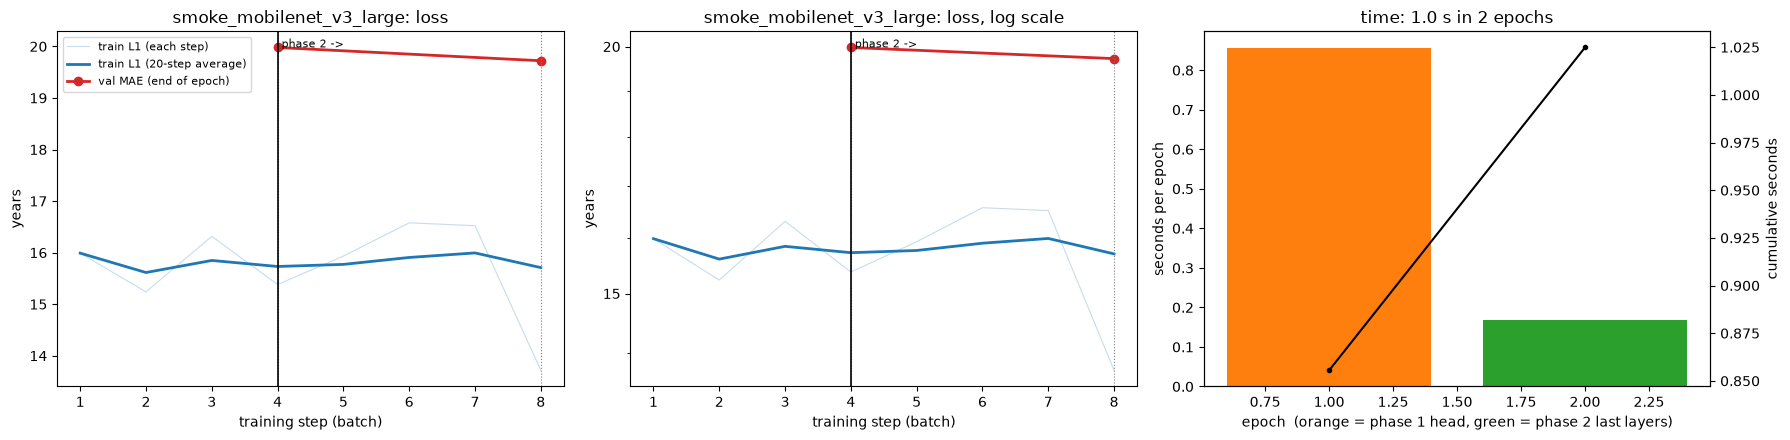

In [9]:
for name in ("resnet18", "mobilenet_v3_large"):
    print(f"--- {name} ---")
    _ = train_model(name, run_name=f"smoke_{name}", kind="test", n_train=512, n_val=256, max_epochs=2)

## 10 · Full training runs (started with the user's OK, 2026-11-18)

**run01 used the first version of step 9**: early stopping with patience 3, a 3-image last batch, random head weights. These were fixed afterwards (see section 11); run01 stays in the logs because every run counts.

Same settings for both models: all 16,131 training images, full val set (3,461), option A (1 epoch head, then last layers), max 15 epochs, early stopping patience 3, L1, bf16, batch 128, seed 655, `cuda:0`, lab machine.

Each cell trains only if its run is not yet in `logs/runs.csv`; otherwise it loads the saved best weights, so re-running the notebook never trains again by accident. **The test set is not used here.**

### 10.1 · ResNet18

  original head: Linear(in_features=512, out_features=1000, bias=True)
  new head     : Linear(in_features=512, out_features=1, bias=True)


epoch  1 [head]  train L1 14.323  |  val MAE 13.389  |  lr 1.0e-03  |   1.4 s


epoch  2 [last]  train L1  7.659  |  val MAE  6.720  |  lr 1.0e-03  |   1.9 s


epoch  3 [last]  train L1  6.035  |  val MAE  5.637  |  lr 9.9e-04  |   1.2 s


epoch  4 [last]  train L1  5.550  |  val MAE  6.561  |  lr 9.5e-04  |   1.2 s


epoch  5 [last]  train L1  5.254  |  val MAE  5.313  |  lr 8.9e-04  |   1.2 s


epoch  6 [last]  train L1  4.989  |  val MAE  5.412  |  lr 8.1e-04  |   1.2 s


epoch  7 [last]  train L1  4.741  |  val MAE  5.297  |  lr 7.2e-04  |   1.2 s


epoch  8 [last]  train L1  4.638  |  val MAE  5.349  |  lr 6.1e-04  |   1.2 s


epoch  9 [last]  train L1  4.414  |  val MAE  5.301  |  lr 5.0e-04  |   1.2 s


epoch 10 [last]  train L1  4.194  |  val MAE  5.429  |  lr 3.9e-04  |   1.2 s
early stop: val MAE did not improve for 3 epochs
[resnet18_A_run01] ok | 14.7 s | 1.981 Wh (cpu 0.022, gpu 1.918, ram 0.041) | 0.920 g CO2eq
best val MAE 5.297 at epoch 7  ->  checkpoints/resnet18_A_run01.pt  |  total 15.9 s


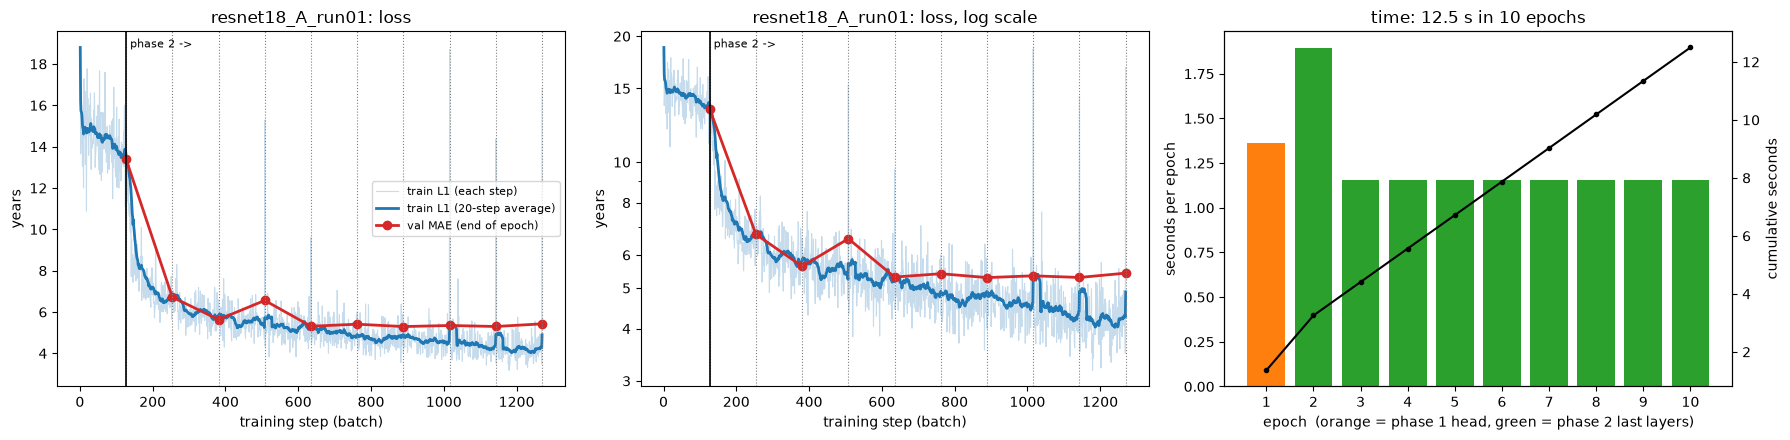

In [9]:
RUN_RESNET = "resnet18_A_run01"

if already_logged(RUN_RESNET):
    print(f"{RUN_RESNET} already trained - loading its best weights (no training)")
    resnet = build_model("resnet18").to(DEV)
    resnet.load_state_dict(torch.load(CKPT_DIR / f"{RUN_RESNET}.pt"))
    hist_resnet = pd.read_csv(TRAIN_LOG_DIR / f"{RUN_RESNET}.csv")
else:
    resnet, hist_resnet = train_model("resnet18", RUN_RESNET)

### 10.2 · MobileNetV3-Large

  original head: Linear(in_features=1280, out_features=1000, bias=True)
  new head     : Linear(in_features=1280, out_features=1, bias=True)


epoch  1 [head]  train L1 13.468  |  val MAE 12.103  |  lr 1.0e-03  |   1.8 s


epoch  2 [last]  train L1  8.488  |  val MAE  7.258  |  lr 1.0e-03  |   4.4 s


epoch  3 [last]  train L1  6.434  |  val MAE  6.108  |  lr 9.9e-04  |   1.7 s


epoch  4 [last]  train L1  5.850  |  val MAE  5.946  |  lr 9.5e-04  |   1.7 s


epoch  5 [last]  train L1  5.432  |  val MAE  5.834  |  lr 8.9e-04  |   1.7 s


... (6 outputs left out)

epoch 12 [last]  train L1  4.254  |  val MAE  5.293  |  lr 1.9e-04  |   1.7 s


epoch 13 [last]  train L1  4.157  |  val MAE  5.264  |  lr 1.1e-04  |   1.7 s


epoch 14 [last]  train L1  4.110  |  val MAE  5.275  |  lr 5.0e-05  |   1.7 s


epoch 15 [last]  train L1  4.091  |  val MAE  5.280  |  lr 1.3e-05  |   1.7 s
[mobilenet_v3_large_A_run01] ok | 31.8 s | 4.059 Wh (cpu 0.047, gpu 3.924, ram 0.088) | 1.886 g CO2eq
best val MAE 5.264 at epoch 13  ->  checkpoints/mobilenet_v3_large_A_run01.pt  |  total 31.8 s


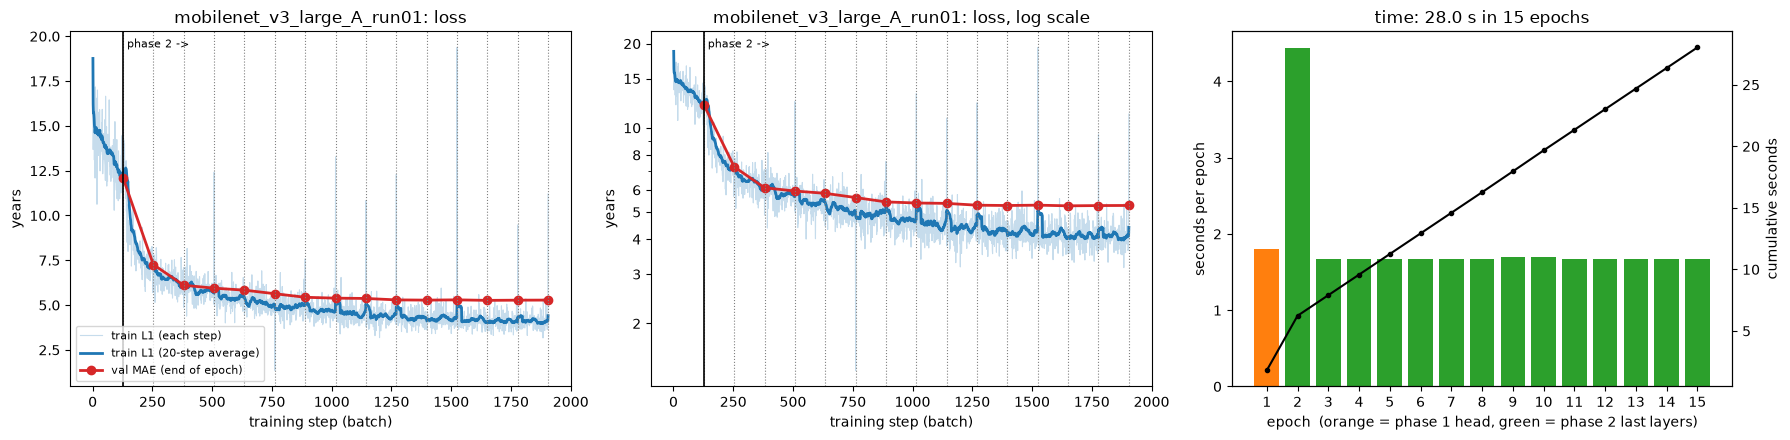

In [10]:
RUN_MNV3 = "mobilenet_v3_large_A_run01"

if already_logged(RUN_MNV3):
    print(f"{RUN_MNV3} already trained - loading its best weights (no training)")
    mnv3 = build_model("mobilenet_v3_large").to(DEV)
    mnv3.load_state_dict(torch.load(CKPT_DIR / f"{RUN_MNV3}.pt"))
    hist_mnv3 = pd.read_csv(TRAIN_LOG_DIR / f"{RUN_MNV3}.csv")
else:
    mnv3, hist_mnv3 = train_model("mobilenet_v3_large", RUN_MNV3)

## 11 · Fixed protocol (run02) and full fine-tuning (user request, 2026-11-18)

Three fixes after run01 (details in the step 9 table): **exactly 15 epochs, no early stopping** (cosine lr reaches 0; best val epoch kept), **only full batches** (126 per epoch), **head weights = 0** (start = mean baseline).

Four runs, **same settings except the strategy**, so the comparison is fair:

| run | strategy | what trains |
|---|---|---|
| `resnet18_A_run02` | A | epoch 1 head only; epochs 2–15 `layer3`, `layer4`, `fc` |
| `mobilenet_v3_large_A_run02` | A | epoch 1 head only; epochs 2–15 `features[7:]`, `classifier` |
| `resnet18_full_run01` | full | all 11.18 M parameters, epochs 1–15 |
| `mobilenet_v3_large_full_run01` | full | all 4.20 M parameters, epochs 1–15 |

Question: does full fine-tuning give a lower val MAE, and how much more energy does it cost? Each run trains only if it is not yet logged; otherwise its best weights are loaded. **Test set not used.**

In [10]:
def train_or_load(name, run_name, strategy):
    """Train once; if the run is already logged, load its best weights instead (no training)."""
    if already_logged(run_name):
        print(f"{run_name} already trained - loading its best weights (no training)")
        model = build_model(name).to(DEV)
        model.load_state_dict(torch.load(CKPT_DIR / f"{run_name}.pt"))
        return model, pd.read_csv(TRAIN_LOG_DIR / f"{run_name}.csv")
    print(f"=== {run_name} ===")
    return train_model(name, run_name, strategy=strategy)

RUNS_V2 = {   # run name -> (model name, strategy)
    "resnet18_A_run02":              ("resnet18", "A"),
    "mobilenet_v3_large_A_run02":    ("mobilenet_v3_large", "A"),
    "resnet18_full_run01":           ("resnet18", "full"),
    "mobilenet_v3_large_full_run01": ("mobilenet_v3_large", "full"),
}
models_v2, hists_v2 = {}, {}
for run_name, (name, strategy) in RUNS_V2.items():
    models_v2[run_name], hists_v2[run_name] = train_or_load(name, run_name, strategy)

resnet18_A_run02 already trained - loading its best weights (no training)
  original head: Linear(in_features=512, out_features=1000, bias=True)
  new head     : Linear(in_features=512, out_features=1, bias=True)
mobilenet_v3_large_A_run02 already trained - loading its best weights (no training)
  original head: Linear(in_features=1280, out_features=1000, bias=True)
  new head     : Linear(in_features=1280, out_features=1, bias=True)


resnet18_full_run01 already trained - loading its best weights (no training)


  original head: Linear(in_features=512, out_features=1000, bias=True)
  new head     : Linear(in_features=512, out_features=1, bias=True)
mobilenet_v3_large_full_run01 already trained - loading its best weights (no training)
  original head: Linear(in_features=1280, out_features=1000, bias=True)
  new head     : Linear(in_features=1280, out_features=1, bias=True)


### 11.1 · Comparison of all standard-model runs (val only)

One row per training run: best val MAE, the epoch it was reached, time, energy and CO2 (from `logs/runs.csv`, measured by CodeCarbon). The plot shows val MAE per epoch for every run, and energy per run.

                          run  best_val_mae  best_epoch  epochs_run  duration_s    Wh  Wh / epoch  g CO2
             resnet18_A_run01         5.297       7.000      10.000      14.700 1.981       0.198  0.920
   mobilenet_v3_large_A_run01         5.264      13.000      15.000      31.800 4.059       0.271  1.886
             resnet18_A_run02         4.993      12.000      15.000      21.200 3.015       0.201  1.401
   mobilenet_v3_large_A_run02         5.242       9.000      15.000      29.200 4.046       0.270  1.880
          resnet18_full_run01         4.761      15.000      15.000      43.600 5.714       0.381  2.654
mobilenet_v3_large_full_run01         5.092      14.000      15.000      68.500 7.533       0.502  3.500


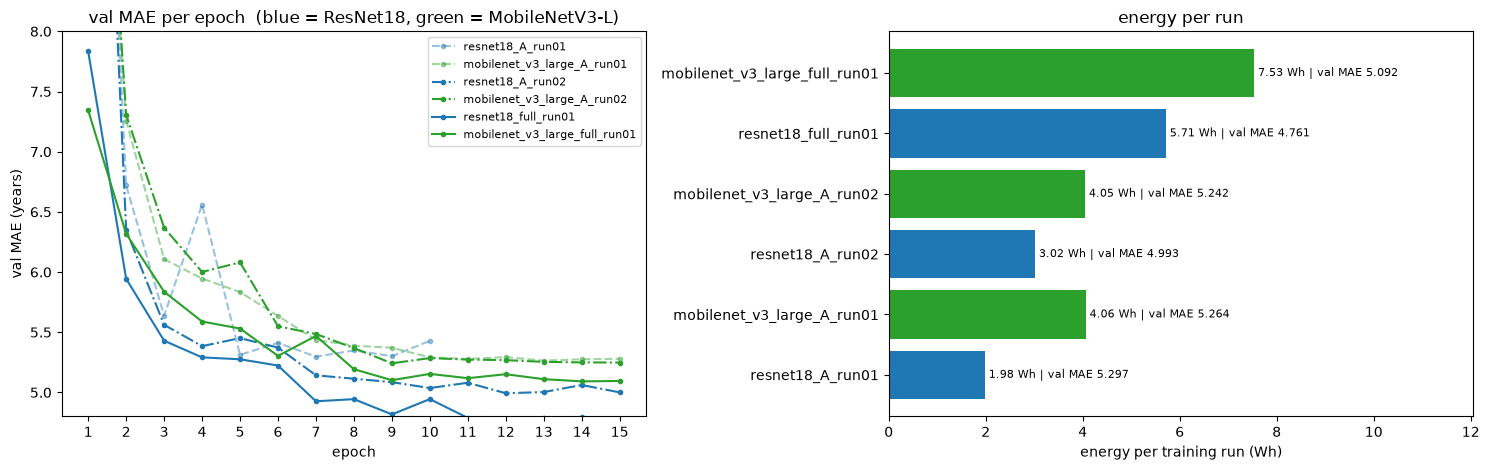


project total so far: 30.21 Wh, 14.03 g CO2eq


In [10]:
runs = pd.read_csv(RUNS_CSV)
train_runs = runs[(runs.kind == "train") & (runs.status == "ok")].copy()
train_runs["Wh"] = 1000 * train_runs.energy_kwh
train_runs["g CO2"] = 1000 * train_runs.kg_co2
train_runs["Wh / epoch"] = train_runs.Wh / train_runs.epochs_run
cols = ["run", "best_val_mae", "best_epoch", "epochs_run", "duration_s", "Wh", "Wh / epoch", "g CO2"]
with pd.option_context("display.width", 200, "display.float_format", "{:.3f}".format):
    print(train_runs[cols].to_string(index=False))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.8))
for run in train_runs.run:
    h = pd.read_csv(TRAIN_LOG_DIR / f"{run}.csv")
    style = "-" if "_full_" in run else ("--" if "run01" in run else "-.")
    color = "tab:blue" if run.startswith("resnet18") else "tab:green"
    ax1.plot(h.epoch, h.val_mae, style, marker="o", ms=3, color=color,
             alpha=0.45 if run.endswith("A_run01") else 1, label=run)
ax1.set_ylim(4.8, 8); ax1.set_xlabel("epoch"); ax1.set_ylabel("val MAE (years)")
ax1.set_title("val MAE per epoch  (blue = ResNet18, green = MobileNetV3-L)")
ax1.legend(fontsize=8); ax1.set_xticks(range(1, 16))
ax2.barh(train_runs.run, train_runs.Wh, color=["tab:blue" if r.startswith("resnet18") else "tab:green" for r in train_runs.run])
for y, (wh, mae) in enumerate(zip(train_runs.Wh, train_runs.best_val_mae)):
    ax2.text(wh, y, f" {wh:.2f} Wh | val MAE {mae:.3f}", va="center", fontsize=8)
ax2.set_xlabel("energy per training run (Wh)"); ax2.set_title("energy per run"); ax2.set_xlim(0, train_runs.Wh.max() * 1.6)
plt.tight_layout(); fig.savefig(FIG_DIR / "compare_standard_runs.png", dpi=110); plt.show()
print(f"\nproject total so far: {1000 * runs.energy_kwh.sum():.2f} Wh, {1000 * runs.kg_co2.sum():.2f} g CO2eq")

## 12 · Test evaluation: once per final configuration (user decision, 2026-11-18)

The four configurations of section 11 are the **final standard models**; nothing was chosen using test. Each one gets **exactly one** pass over the 3,461 test images (`kind="eval"`, logged). If its evaluation is already in `logs/runs.csv`, the stored result is shown instead, so the test set can never be used twice by re-running the notebook.

Per model, the columns of the assignment table (3.5):
- **test MAE, RMSE, R²** + per-group MAE → `results/per_group/<run>_test.csv`
- **params**, **MFLOPs / image** = 2 × MACs (1 MAC = 1 multiply + 1 add = 2 FLOPs), at 200 px
- **train kWh / kg CO2** of the final training run, from `logs/runs.csv`
- **model file size** (MB) of the saved weights
- **latency (ms / image)**: batch size 1, median of 300 single images on the RTX 5090 (after 20 warm-up images)
- **energy per 1,000 predictions**: one test pass takes < 1 s, too short for CodeCarbon (it samples every 5 s), so this is measured separately by predicting the **val** images repeatedly for ~10 s at batch 512 and dividing the energy by the number of predictions. Energy per prediction does not depend on which faces are used, and using val keeps the test set to a single pass.

In [11]:
import os

FINAL = {   # run name -> (model name, strategy, label in the results table)
    "resnet18_A_run02":              ("resnet18", "A", "ResNet18 (A: head, then layer3-4)"),
    "mobilenet_v3_large_A_run02":    ("mobilenet_v3_large", "A", "MobileNetV3-L (A: head, then blocks 7-16)"),
    "resnet18_full_run01":           ("resnet18", "full", "ResNet18 (full fine-tuning)"),
    "mobilenet_v3_large_full_run01": ("mobilenet_v3_large", "full", "MobileNetV3-L (full fine-tuning)"),
}

# test images to the GPU (uint8, 3,461 x 3 x 200 x 200 = 0.42 GB); rows in split order
te_idx = np.flatnonzero(split_df.split.values == "test")
X_test = torch.from_numpy(np.array(images[te_idx])).to(DEV)
y_test = split_df.age.values[te_idx]
test_meta = split_df.iloc[te_idx].reset_index(drop=True)      # gender / race / age band of each test image


@torch.no_grad()
def latency_ms(model, n=300, warmup=20):
    """Median time to predict ONE image (batch size 1), in milliseconds."""
    model.eval()
    times = []
    for i in range(warmup + n):
        x = make_batch(X_val, torch.tensor([i], device=DEV), train=False)
        torch.cuda.synchronize(); t0 = time.perf_counter()
        with torch.autocast("cuda", dtype=torch.bfloat16):
            model(x)
        torch.cuda.synchronize()                    # wait until the GPU has really finished
        if i >= warmup:
            times.append(1000 * (time.perf_counter() - t0))
    return float(np.median(times))


def evaluate_on_test(run_name):
    name, strategy, label = FINAL[run_name]
    eval_run = f"eval_test_{run_name}"
    if already_logged(eval_run):                     # never touch the test set twice
        print(f"{eval_run} already done - showing stored result")
        return pd.read_csv(RESULTS_CSV).set_index("run").loc[run_name].to_dict() | {"run": run_name}

    model = models_v2[run_name]                      # best weights, loaded/trained in section 11

    # 1) the single test pass: metrics + per-group error
    with track(eval_run, kind="eval", gpu_ids=[0], notes=f"single test pass, {label}") as info:
        pred = predict(model, X_test).cpu().numpy()
        metrics, groups = evaluate(y_test, pred, test_meta)
        info.update({"test_mae": round(metrics["mae"], 4)})
    groups.to_csv(GROUP_DIR / f"{run_name}_test.csv", index=False)

    # 2) energy per 1,000 predictions: predict the VAL images repeatedly for ~10 s
    with track(f"bench_{run_name}", kind="eval", gpu_ids=[0], notes="energy per prediction, val images, batch 512") as info:
        n_pred, t0 = 0, time.time()
        while time.time() - t0 < 10:
            predict(model, X_val); n_pred += len(X_val)
        torch.cuda.synchronize()
        info["n_predictions"] = n_pred
    bench_name = f"bench_{run_name}"
    bench = pd.read_csv(RUNS_CSV).query("run == @bench_name").iloc[-1]
    wh_per_1000 = 1000 * bench.energy_kwh / (n_pred / 1000)

    # 3) size, compute, latency, training cost
    macs = sum(macs_per_module(build_model(name)).values())        # on CPU, one 200x200 image
    train_row = pd.read_csv(RUNS_CSV).query("run == @run_name").iloc[-1]
    row = {"model": label, "run": run_name, "machine": MACHINE, "strategy": strategy,
           "params": n_params(model), "mflops_per_img": round(2 * macs / 1e6, 1),
           "val_mae": round(train_row.best_val_mae, 3),
           "test_mae": round(metrics["mae"], 3), "test_rmse": round(metrics["rmse"], 3), "test_r2": round(metrics["r2"], 4),
           "train_kwh": train_row.energy_kwh, "train_kg_co2": train_row.kg_co2,
           "project_kg_co2": None,                                   # filled in after all evaluations
           "ms_per_img": round(latency_ms(model), 3), "wh_per_1000_pred": round(wh_per_1000, 4),
           "size_mb": round(os.path.getsize(CKPT_DIR / f"{run_name}.pt") / 1e6, 2)}
    save_result(row)
    return row


rows = [evaluate_on_test(r) for r in FINAL]

# project CO2 per model family = every logged run of that architecture (smoke, run01, run02/full, evals, benches)
runs_log = pd.read_csv(RUNS_CSV)
res = pd.read_csv(RESULTS_CSV)
for fam in ("resnet18", "mobilenet_v3_large"):
    fam_kg = runs_log[runs_log.run.str.contains(fam)].kg_co2.sum()
    res.loc[res.run.astype(str).str.startswith(fam), "project_kg_co2"] = fam_kg
res.to_csv(RESULTS_CSV, index=False)

cols = ["model", "params", "mflops_per_img", "val_mae", "test_mae", "test_rmse", "test_r2",
        "train_kwh", "train_kg_co2", "project_kg_co2", "ms_per_img", "wh_per_1000_pred", "size_mb"]
with pd.option_context("display.width", 250, "display.max_columns", 20):
    print(res[cols].to_string(index=False))

std = res[res.run.astype(str).isin(FINAL)]
best = std.loc[std.test_mae.idxmin()]
mae_mean = res.loc[res.model == "mean baseline", "test_mae"].item()
print(f"\nMAE_best = {best.test_mae:.3f}  ({best.model})")
print(f"own CNN must reach:  MAE_own <= 1.15 x {best.test_mae:.3f} = {1.15 * best.test_mae:.3f}"
      f"   and   MAE_own <= 0.6 x {mae_mean:.3f} = {0.6 * mae_mean:.3f}")
print(f"-> binding limit: {min(1.15 * best.test_mae, 0.6 * mae_mean):.3f} years")

eval_test_resnet18_A_run02 already done - showing stored result
eval_test_mobilenet_v3_large_A_run02 already done - showing stored result
eval_test_resnet18_full_run01 already done - showing stored result
eval_test_mobilenet_v3_large_full_run01 already done - showing stored result
                                    model   params  mflops_per_img  val_mae  test_mae  test_rmse  test_r2  train_kwh  train_kg_co2  project_kg_co2  ms_per_img  wh_per_1000_pred  size_mb
                            mean baseline        0             0.0      NaN    15.400     20.007  -0.0000   0.000000      0.000000             NaN       0.000               NaN      NaN
                          median baseline        0             0.0      NaN    15.072     20.471  -0.0470   0.000000      0.000000             NaN       0.000               NaN      NaN
        ResNet18 (A: head, then layer3-4) 11177025          3111.7    4.993     4.888      6.996   0.8777   0.003015      0.001401        0.006513       0.804  

### 12.1 · Findings in four plots

Plotting only (reads `results/results.csv`, `logs/runs.csv`, `logs/train/*.csv`, `results/per_group/*.csv`); nothing is trained or evaluated, so nothing is measured.

- **(a) Test MAE vs training CO2** (log x-axis, as in assignment 3.5), the **Pareto front** (no other model is both more accurate and cheaper), and the own-CNN limit 1.15 × MAE_best.
- **(b) FLOPs are not energy:** MFLOPs per image vs measured energy per training epoch.
- **(c) Test MAE per age band**: mean baseline vs the four models.
- **(d) Val MAE vs test MAE**: points on the diagonal mean val predicted test well.

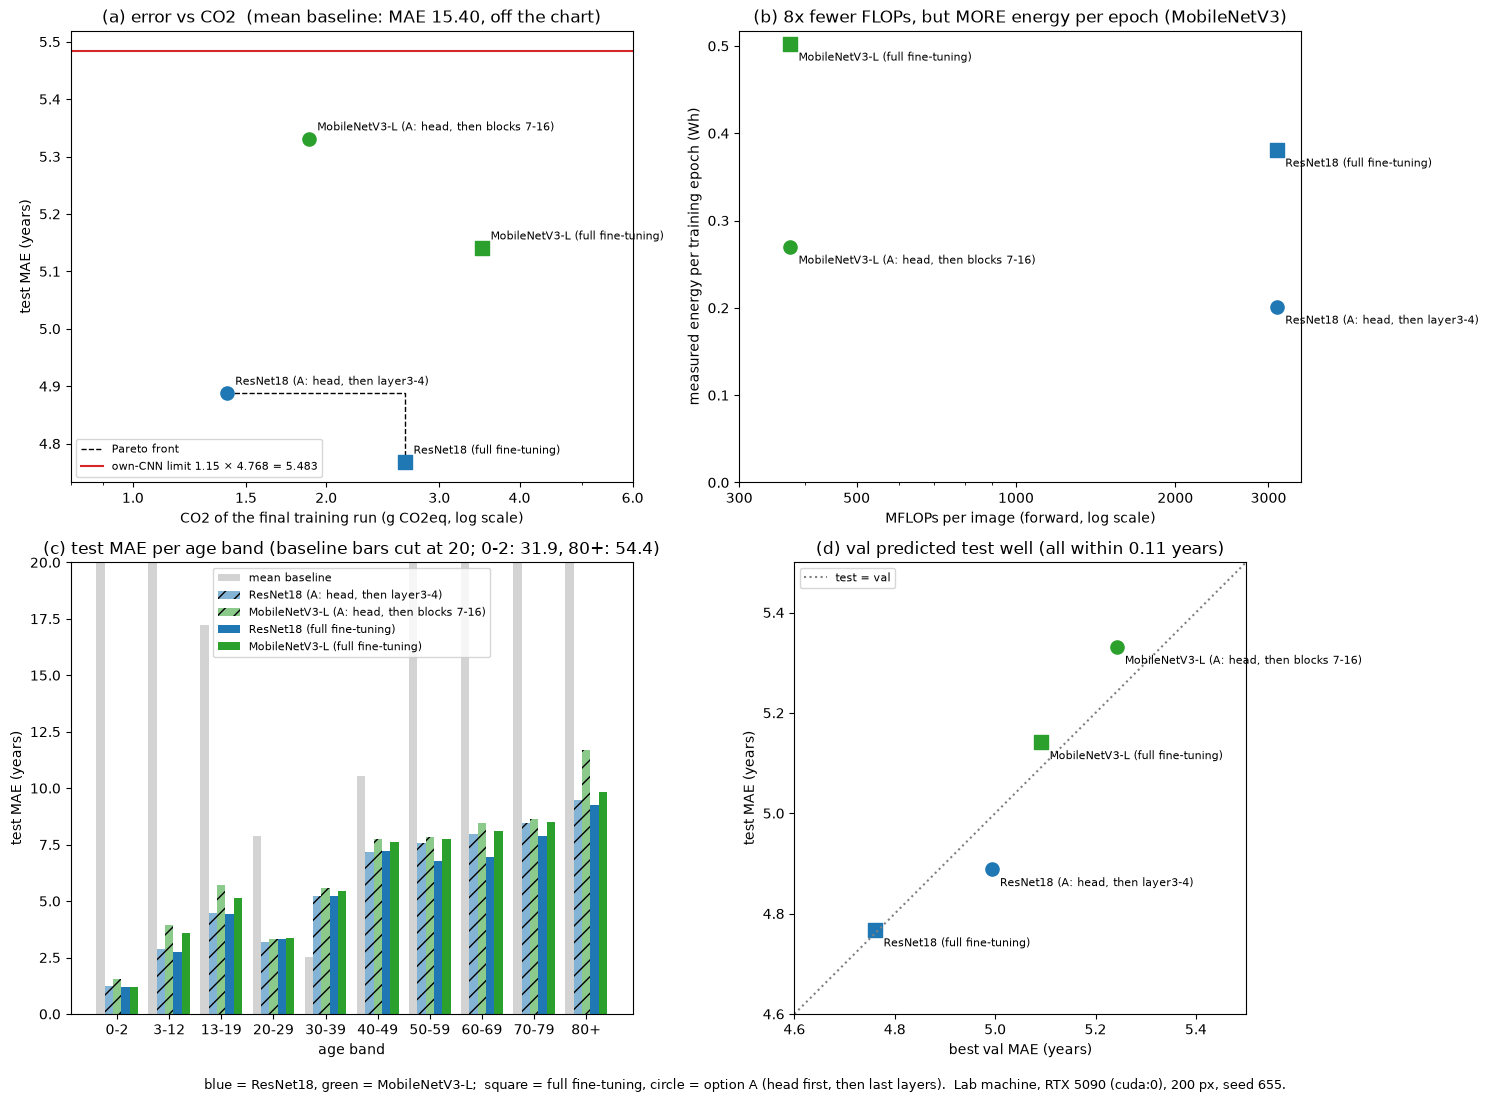

Pareto front (cheapest first):
                            model  train g CO2  test_mae
ResNet18 (A: head, then layer3-4)        1.401     4.888
      ResNet18 (full fine-tuning)        2.654     4.768


In [12]:
res = pd.read_csv(RESULTS_CSV)
runs_log = pd.read_csv(RUNS_CSV)
std = res[res.run.astype(str).isin(FINAL)].copy()
std["train_g"] = 1000 * std.train_kg_co2
std["color"] = ["tab:blue" if r.startswith("resnet18") else "tab:green" for r in std.run]
std["marker"] = ["s" if s == "full" else "o" for s in std.strategy]
mae_best = std.test_mae.min()
limit = 1.15 * mae_best

fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# (a) error vs CO2 with Pareto front -----------------------------------------------------------
ax = axes[0, 0]
for _, r in std.iterrows():
    ax.scatter(r.train_g, r.test_mae, s=90, color=r.color, marker=r.marker, zorder=3)
    ax.annotate(r.model, (r.train_g, r.test_mae), textcoords="offset points", xytext=(6, 6), fontsize=8)
pareto, best_so_far = [], np.inf                     # walk from cheapest to most expensive
for _, r in std.sort_values("train_g").iterrows():
    if r.test_mae < best_so_far:                     # more accurate than every cheaper model -> on the front
        pareto.append(r); best_so_far = r.test_mae
pareto = pd.DataFrame(pareto)
ax.step(pareto.train_g, pareto.test_mae, where="post", color="black", lw=1, ls="--", label="Pareto front")
ax.axhline(limit, color="tab:red", lw=1.5, label=f"own-CNN limit 1.15 × {mae_best:.3f} = {limit:.3f}")
ax.set_xscale("log"); ax.set_xlabel("CO2 of the final training run (g CO2eq, log scale)")
ax.set_ylabel("test MAE (years)"); ax.set_title("(a) error vs CO2  (mean baseline: MAE 15.40, off the chart)")
ax.legend(fontsize=8, loc="lower left"); ax.set_xlim(0.8, 6)
ax.set_xticks([1, 1.5, 2, 3, 4, 6]); ax.xaxis.set_major_formatter(plt.ScalarFormatter()); ax.xaxis.set_minor_formatter(plt.NullFormatter())

# (b) FLOPs vs measured energy per epoch ----------------------------------------------------------
ax = axes[0, 1]
for _, r in std.iterrows():
    tr = runs_log.query("run == @r.run").iloc[-1]
    wh_epoch = 1000 * tr.energy_kwh / tr.epochs_run
    ax.scatter(r.mflops_per_img, wh_epoch, s=90, color=r.color, marker=r.marker)
    ax.annotate(r.model, (r.mflops_per_img, wh_epoch), textcoords="offset points", xytext=(6, -12), fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("MFLOPs per image (forward, log scale)")
ax.set_xticks([300, 500, 1000, 2000, 3000]); ax.xaxis.set_major_formatter(plt.ScalarFormatter()); ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_ylabel("measured energy per training epoch (Wh)")
ax.set_title("(b) 8x fewer FLOPs, but MORE energy per epoch (MobileNetV3)")
ax.set_ylim(0, None)

# (c) test MAE per age band -----------------------------------------------------------------------
ax = axes[1, 0]
bands = AGE_BANDS
base = pd.read_csv(GROUP_DIR / "baseline_mean_test.csv").query("group == 'age_band'").set_index("value").loc[bands]
ax.bar(np.arange(len(bands)) - 0.4, base.mae, width=0.16, color="lightgrey", label="mean baseline", align="edge")
for k, (_, r) in enumerate(std.iterrows()):
    g = pd.read_csv(GROUP_DIR / f"{r.run}_test.csv").query("group == 'age_band'").set_index("value").loc[bands]
    ax.bar(np.arange(len(bands)) - 0.24 + 0.16 * k, g.mae, width=0.16, align="edge", color=r.color,
           alpha=1 if r.strategy == "full" else 0.55, hatch="" if r.strategy == "full" else "//", label=r.model)
ax.set_xticks(range(len(bands))); ax.set_xticklabels(bands)
ax.set_xlabel("age band"); ax.set_ylabel("test MAE (years)"); ax.set_ylim(0, 20)
ax.set_title("(c) test MAE per age band (baseline bars cut at 20; 0-2: 31.9, 80+: 54.4)")
ax.legend(fontsize=8)

# (d) val vs test MAE ---------------------------------------------------------------------------------
ax = axes[1, 1]
for _, r in std.iterrows():
    ax.scatter(r.val_mae, r.test_mae, s=90, color=r.color, marker=r.marker)
    ax.annotate(r.model, (r.val_mae, r.test_mae), textcoords="offset points", xytext=(6, -12), fontsize=8)
lo, hi = 4.6, 5.5
ax.plot([lo, hi], [lo, hi], color="grey", ls=":", label="test = val")
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
ax.set_xlabel("best val MAE (years)"); ax.set_ylabel("test MAE (years)")
ax.set_title("(d) val predicted test well (all within 0.11 years)"); ax.legend(fontsize=8)

fig.text(0.5, 0.005, "blue = ResNet18, green = MobileNetV3-L;  square = full fine-tuning, circle = option A "
         "(head first, then last layers).  Lab machine, RTX 5090 (cuda:0), 200 px, seed 655.", ha="center", fontsize=9)
plt.tight_layout(rect=(0, 0.02, 1, 1))
fig.savefig(FIG_DIR / "findings_standard_models.png", dpi=120)
plt.show()

print("Pareto front (cheapest first):")
print(pareto[["model", "train_g", "test_mae"]].rename(columns={"train_g": "train g CO2"}).round(3).to_string(index=False))

## 13 · Is the model biased by age? Error per age band (val set, user question 2026-11-18)

Question: UTKFace has many more 20–39-year-olds than children or old people. Does the model therefore
predict some ages systematically too high or too low?

**Why the val set and not test:** the answer may change how we train (re-weighting / balancing) = a tuning decision.
The test set must never influence tuning, so this analysis uses validation predictions only.

**Two different errors per age band**
- MAE = mean |pred − age|: *how far off* (always ≥ 0).
- bias = mean (pred − age): *in which direction*. +3 = predicts 3 years too old on average; −3 = too young.
  A model can have a large MAE but bias 0 (errors both ways cancel), so we need both.

Hand example: three 70-year-olds predicted 62, 66, 75 → errors −8, −4, +5 → MAE = 17/3 = 5.67, bias = −7/3 = −2.33 (too young).

**What we expect (regression to the mean):** with L1/L2 loss the model is rewarded for guessing towards the dense middle
when it is unsure, so ages *below* the dense region get positive bias, ages *above* it negative bias.

ResNet18 full - validation set, per age band
          n_train  n_val  mean_age   mae  bias  pct_too_old  rel_mae_pct
age_band                                                                
0-2          1117    238       1.3  1.08  0.06         45.0         84.1
3-12         1234    266       6.7  2.78  1.10         51.0         41.2
13-19         800    172      16.4  4.75  2.52         66.0         29.0
20-29        4964   1064      25.4  3.60  2.00         66.0         14.1
30-39        3100    666      33.9  5.46 -0.09         42.0         16.1
40-49        1531    328      43.6  6.60 -2.26         35.0         15.1
50-59        1565    335      53.9  6.51 -1.99         43.0         12.1
60-69         892    192      63.5  6.31 -1.84         42.0          9.9
70-79         470    101      73.5  7.41 -4.55         35.0         10.1
80+           458     99      86.3  9.08 -7.61         21.0         10.5

overall: MAE 4.762, bias -0.051 years  (mean prediction 33.21 vs mean true age


Spearman(n_train, MAE) = -0.42   Spearman(n_train, relative MAE) = +0.28


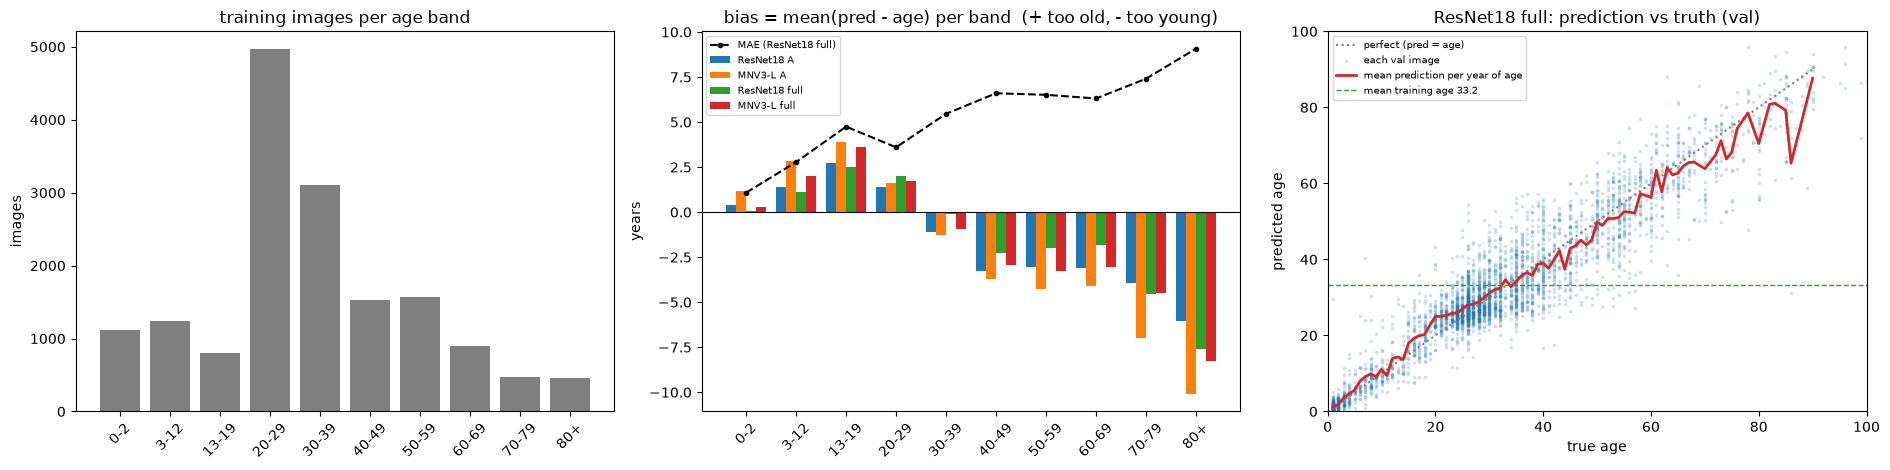

In [11]:
PRED_DIR = REPO / "results" / "predictions"     # per-image predictions (val only), reusable without the GPU
PRED_DIR.mkdir(parents=True, exist_ok=True)
BIAS_RUN = "eval_val_error_by_age"
LABEL = {"resnet18_A_run02": "ResNet18 A", "mobilenet_v3_large_A_run02": "MNV3-L A",      # short names for the plots
         "resnet18_full_run01": "ResNet18 full", "mobilenet_v3_large_full_run01": "MNV3-L full"}

# 1) one val prediction pass per model (4 x 3,461 images), measured once with CodeCarbon
assert np.array_equal(y_val.cpu().numpy(), val.age.values), "X_val rows must be in the same order as `val`"
if not already_logged(BIAS_RUN):
    with track(BIAS_RUN, kind="eval", gpu_ids=[0], notes="val predictions of the 4 standard models for the error-by-age analysis") as info:
        for run_name in RUNS_V2:
            pred = predict(models_v2[run_name], X_val).cpu().numpy()
            out = val[["file", "age", "age_band", "gender", "race"]].assign(pred=pred.round(3))
            out.to_csv(PRED_DIR / f"val_{run_name}.csv", index=False)
preds = {r: pd.read_csv(PRED_DIR / f"val_{r}.csv") for r in RUNS_V2}

# 2) table per age band: how many TRAINING images, MAE, bias (signed), relative error
train_n = train.age_band.value_counts().reindex(AGE_BANDS)
rows = []
for r, d in preds.items():
    d = d.assign(err=d.pred - d.age)                         # signed error: + = too old, - = too young
    for band, g in d.groupby("age_band"):
        rows.append({"run": r, "age_band": band, "n_val": len(g), "n_train": train_n[band],
                     "mean_age": g.age.mean(), "mae": g.err.abs().mean(), "bias": g.err.mean(),
                     "pct_too_old": 100 * (g.err > 0).mean(),
                     "rel_mae_pct": 100 * g.err.abs().mean() / g.age.mean()})   # MAE relative to the age itself
band_tab = pd.DataFrame(rows)
band_tab["age_band"] = pd.Categorical(band_tab.age_band, AGE_BANDS, ordered=True)
band_tab = band_tab.sort_values(["run", "age_band"])

best_run = "resnet18_full_run01"
t = band_tab[band_tab.run == best_run].set_index("age_band")
print(f"{LABEL[best_run]} - validation set, per age band")
print(t[["n_train", "n_val", "mean_age", "mae", "bias", "pct_too_old", "rel_mae_pct"]]
      .round({"mean_age": 1, "mae": 2, "bias": 2, "pct_too_old": 0, "rel_mae_pct": 1}).to_string())
overall = preds[best_run].assign(err=lambda d: d.pred - d.age)
print(f"\noverall: MAE {overall.err.abs().mean():.3f}, bias {overall.err.mean():+.3f} years  "
      f"(mean prediction {overall.pred.mean():.2f} vs mean true age {overall.age.mean():.2f})")

print("\nbias (years, + = too old) per age band, all four models:")
print(band_tab.pivot(index="age_band", columns="run", values="bias").rename(columns=LABEL).round(2).to_string())

# is the error explained by how many training images a band has?  (Spearman = rank correlation)
c_abs = t.n_train.corr(t.mae, method="spearman")
c_rel = t.n_train.corr(t.rel_mae_pct, method="spearman")
print(f"\nSpearman(n_train, MAE) = {c_abs:+.2f}   Spearman(n_train, relative MAE) = {c_rel:+.2f}")

# 3) figure: data per band | MAE + bias per band | mean prediction vs true age (1-year bins)
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
ax = axes[0]
ax.bar(AGE_BANDS, train_n.values, color="grey")
ax.set_title("training images per age band"); ax.set_ylabel("images"); ax.tick_params(axis="x", rotation=45)

ax = axes[1]
xs = np.arange(len(AGE_BANDS)); w = 0.2
for k, r in enumerate(RUNS_V2):
    b = band_tab[band_tab.run == r]
    ax.bar(xs + (k - 1.5) * w, b.bias, w, label=LABEL[r])
ax.plot(xs, t.mae.values, "k.--", label=f"MAE ({LABEL[best_run]})")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(xs, AGE_BANDS, rotation=45); ax.set_ylabel("years")
ax.set_title("bias = mean(pred - age) per band  (+ too old, - too young)"); ax.legend(fontsize=7)

ax = axes[2]
d = overall.assign(age_bin=overall.age.clip(upper=90))       # few people above 90: pool them
m = d.groupby("age_bin").agg(pred=("pred", "mean"), n=("pred", "size")).query("n >= 5")
ax.plot([0, 90], [0, 90], color="grey", ls=":", label="perfect (pred = age)")
ax.scatter(d.age, d.pred, s=3, alpha=0.15, color="tab:blue", label="each val image")
ax.plot(m.index, m.pred, color="tab:red", lw=2, label="mean prediction per year of age")
ax.axhline(train.age.mean(), color="tab:green", lw=1, ls="--", label=f"mean training age {train.age.mean():.1f}")
ax.set_xlabel("true age"); ax.set_ylabel("predicted age"); ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_title(f"{LABEL[best_run]}: prediction vs truth (val)"); ax.legend(fontsize=7)
plt.tight_layout()
fig.savefig(FIG_DIR / "error_by_age_val.png", dpi=110)
plt.show()
band_tab.round(4).to_csv(REPO / "results" / "error_by_age_val.csv", index=False)

## 14 · One balanced run: ResNet18 full with √(inverse frequency) loss weights (user decision, 2026-11-18)

Section 13 showed regression to the mean: rare young bands predicted too old, rare old bands too young.
Experiment: **the same run as `resnet18_full_run01`** (same seed → same batches, same augmentations, same lr, 15 epochs),
the only change is the loss.

**Weighted L1.** Image *i* in age band *b* gets weight w_b. Batch loss = Σ wᵢ·|predᵢ − ageᵢ| / Σ wᵢ (a weighted average, still in years).

**Weights.** w_b = c / √n_b, with n_b = training images in band b. c is chosen so the average weight over all
16,131 training images is 1: Σ_b n_b·w_b = N → c·Σ_b √n_b = N → **c = N / Σ_b √n_b**.

Hand calculation: √n: 0–2 √1117 = 33.4, 20–29 √4964 = 70.5, 80+ √458 = 21.4, … ; Σ √n_b ≈ 374.6 → c = 16,131 / 374.6 ≈ 43.1.
→ w(20–29) = 43.1 / 70.5 ≈ 0.61, w(80+) = 43.1 / 21.4 ≈ 2.01. One 80+ image now counts 2.01 / 0.61 = √(4964/458) ≈ 3.3× as much as one 20–29 image
(full inverse frequency would be 4964/458 ≈ 10.8×; the square root is the gentler version).

**Fair comparison.** The best epoch is still chosen by the ordinary val MAE, and both runs are compared on the val set only
(the test set is not used: this is an experiment, not a final model). Besides MAE we report the **balanced MAE** = mean of the 10 per-band MAEs
(every age band counts the same), the metric that balancing tries to improve.

N = 16131, sum sqrt(n_b) = 374.6, c = 43.06
          n_train  sqrt_n  weight  share_before_%  share_after_%
age_band                                                        
0-2          1117    33.4   1.288             6.9            8.9
3-12         1234    35.1   1.226             7.6            9.4
13-19         800    28.3   1.522             5.0            7.6
20-29        4964    70.5   0.611            30.8           18.8
30-39        3100    55.7   0.773            19.2           14.9
40-49        1531    39.1   1.101             9.5           10.4
50-59        1565    39.6   1.089             9.7           10.6
60-69         892    29.9   1.442             5.5            8.0
70-79         470    21.7   1.986             2.9            5.8
80+           458    21.4   2.012             2.8            5.7

=== resnet18_full_sqrtw_run01 ===


  original head: Linear(in_features=512, out_features=1000, bias=True)
  new head     : Linear(in_features=512, out_features=1, bias=True)


epoch  1 [full]  train L1  9.787  |  val MAE  6.537  |  lr 1.0e-03  |   3.8 s


epoch  2 [full]  train L1  6.394  |  val MAE  5.863  |  lr 9.9e-04  |   2.7 s


epoch  3 [full]  train L1  5.896  |  val MAE  5.570  |  lr 9.6e-04  |   2.7 s


epoch  4 [full]  train L1  5.590  |  val MAE  5.770  |  lr 9.0e-04  |   2.7 s


... (7 outputs left out)

epoch 12 [full]  train L1  4.072  |  val MAE  4.989  |  lr 1.7e-04  |   2.7 s


epoch 13 [full]  train L1  3.964  |  val MAE  5.020  |  lr 9.5e-05  |   2.7 s


epoch 14 [full]  train L1  3.893  |  val MAE  5.066  |  lr 4.3e-05  |   2.7 s


epoch 15 [full]  train L1  3.938  |  val MAE  4.977  |  lr 1.1e-05  |   2.7 s
[resnet18_full_sqrtw_run01] ok | 44.7 s | 5.644 Wh (cpu 0.067, gpu 5.454, ram 0.124) | 2.622 g CO2eq
best val MAE 4.960 at epoch 8  ->  checkpoints/resnet18_full_sqrtw_run01.pt  |  total 45.9 s


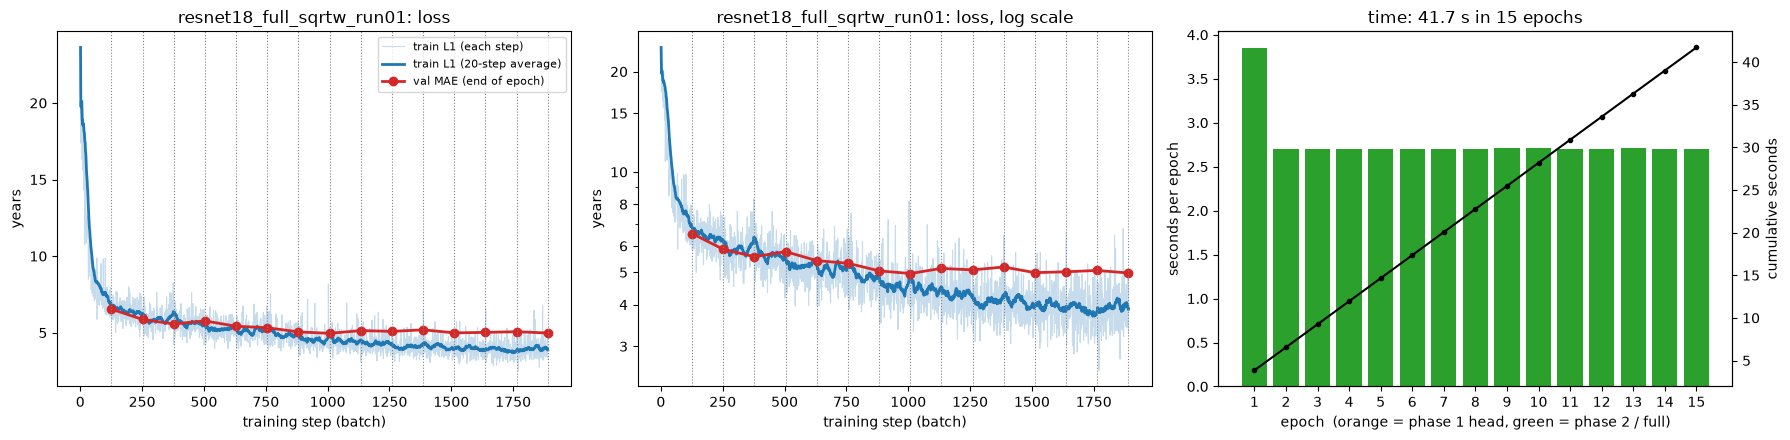

[eval_val_resnet18_full_sqrtw_run01] ok | 0.2 s | 0.018 Wh (cpu 0.000, gpu 0.017, ram 0.000) | 0.008 g CO2eq

val MAE and bias per age band (change = weighted - plain; negative MAE change = better)
               plain L1       weighted L1       change      
         n_val      mae  bias         mae  bias    mae  bias
age_band                                                    
0-2        238     1.08  0.06        0.88  0.14  -0.20  0.08
3-12       266     2.78  1.10        2.79  1.29   0.01  0.19
13-19      172     4.75  2.52        4.41  2.31  -0.34 -0.20
20-29     1064     3.60  2.00        3.94  1.78   0.34 -0.21
30-39      666     5.46 -0.09        5.76 -0.14   0.31 -0.05
40-49      328     6.60 -2.26        7.20 -1.70   0.60  0.56
50-59      335     6.51 -1.99        6.61 -1.73   0.09  0.27
60-69      192     6.31 -1.84        6.59 -2.18   0.28 -0.34
70-79      101     7.41 -4.55        6.96 -3.18  -0.45  1.38
80+         99     9.08 -7.61        8.97 -7.19  -0.11  0.42

        

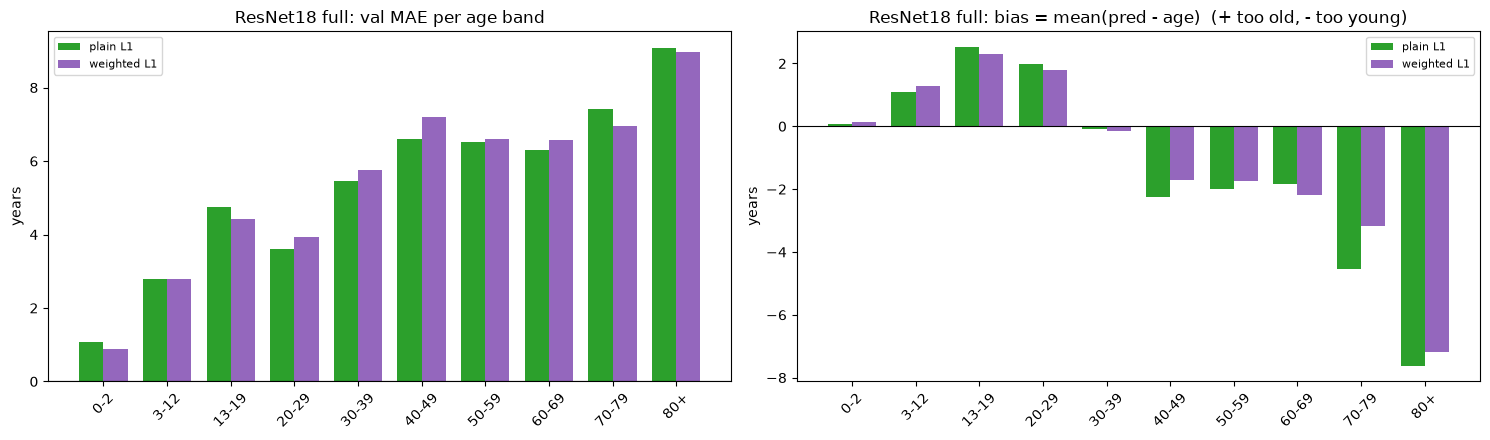

In [12]:
BASE_RUN = "resnet18_full_run01"
BAL_RUN = "resnet18_full_sqrtw_run01"

# 1) one weight per age band: w_b = c / sqrt(n_b), c = N / sum(sqrt(n_b)) -> average weight per image = 1
n_b = train.age_band.value_counts().reindex(AGE_BANDS)
c = len(train) / np.sqrt(n_b).sum()
w_band = c / np.sqrt(n_b)
print(f"N = {len(train)}, sum sqrt(n_b) = {np.sqrt(n_b).sum():.1f}, c = {c:.2f}")
print(pd.DataFrame({"n_train": n_b, "sqrt_n": np.sqrt(n_b).round(1), "weight": w_band.round(3),
                    "share_before_%": (100 * n_b / n_b.sum()).round(1),                       # share of the total loss
                    "share_after_%": (100 * n_b * w_band / (n_b * w_band).sum()).round(1)}).to_string())
assert abs((n_b * w_band).sum() / len(train) - 1) < 1e-9          # average weight is exactly 1

# one weight per training image, in the same row order as X_train
assert np.array_equal(train.age.values, y_train.cpu().numpy().astype(int)), "train rows != X_train rows"
w_train = torch.tensor(train.age_band.map(w_band).values, dtype=torch.float32, device=DEV)

# 2) train once (or load if already trained)
if already_logged(BAL_RUN):
    print(f"\n{BAL_RUN} already trained - loading its best weights (no training)")
    model_bal = build_model("resnet18").to(DEV)
    model_bal.load_state_dict(torch.load(CKPT_DIR / f"{BAL_RUN}.pt"))
else:
    print(f"\n=== {BAL_RUN} ===")
    model_bal, _ = train_model("resnet18", BAL_RUN, strategy="full", sample_weights=w_train)

# 3) val predictions of the new model (one measured pass)
if not already_logged(f"eval_val_{BAL_RUN}"):
    with track(f"eval_val_{BAL_RUN}", kind="eval", gpu_ids=[0], notes="val predictions, balanced-loss experiment"):
        pred = predict(model_bal, X_val).cpu().numpy()
    val[["file", "age", "age_band", "gender", "race"]].assign(pred=pred.round(3)).to_csv(PRED_DIR / f"val_{BAL_RUN}.csv", index=False)

# 4) compare: plain L1 vs weighted L1, per age band and overall
cmp = {"plain L1": pd.read_csv(PRED_DIR / f"val_{BASE_RUN}.csv"),
       "weighted L1": pd.read_csv(PRED_DIR / f"val_{BAL_RUN}.csv")}
per_band, summary = {}, []
for k, d in cmp.items():
    d = d.assign(err=d.pred - d.age)
    g = d.groupby("age_band").err.agg(mae=lambda e: e.abs().mean(), bias="mean").reindex(AGE_BANDS)
    per_band[k] = g
    summary.append({"loss": k, "val MAE": d.err.abs().mean(), "balanced MAE": g.mae.mean(),
                    "bias overall": d.err.mean(), "worst band MAE": g.mae.max()})
both = pd.concat(per_band, axis=1)
both[("change", "mae")] = both[("weighted L1", "mae")] - both[("plain L1", "mae")]
both[("change", "bias")] = both[("weighted L1", "bias")] - both[("plain L1", "bias")]
both.insert(0, ("", "n_val"), val.age_band.value_counts().reindex(AGE_BANDS))
print("\nval MAE and bias per age band (change = weighted - plain; negative MAE change = better)")
print(both.round(2).to_string())
print()
print(pd.DataFrame(summary).set_index("loss").round(3).to_string())

runs_log = pd.read_csv(RUNS_CSV).set_index("run")
print(f"\ntraining energy: plain {1000 * runs_log.loc[BASE_RUN].energy_kwh:.2f} Wh, "
      f"weighted {1000 * runs_log.loc[BAL_RUN].energy_kwh:.2f} Wh")

# 5) figure: MAE per band and bias per band, both losses
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
xs = np.arange(len(AGE_BANDS)); w = 0.38
for ax, col, title in zip(axes, ("mae", "bias"), ("val MAE per age band", "bias = mean(pred - age)  (+ too old, - too young)")):
    for j, (k, color) in enumerate((("plain L1", "tab:green"), ("weighted L1", "tab:purple"))):
        ax.bar(xs + (j - 0.5) * w, per_band[k][col], w, color=color, label=k)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_xticks(xs, AGE_BANDS, rotation=45); ax.set_ylabel("years"); ax.set_title(f"ResNet18 full: {title}")
    ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / "balanced_loss_vs_plain_val.png", dpi=110)
plt.show()

## 15 · Our own CNN (designed with the user 2026-11-18, code in `src/models/own_cnn.py`)

**Goal:** trained from scratch, test MAE ≤ **5.483** (1.15 × ResNet18-full) at the lowest total CO2.

**Design decisions (and why)**
- **Input 200 × 200**, like every other model (same image size policy, professor's requirement).
- **Shrink early:** stem = conv 3×3 stride 2 (200 → 100) + max pool 3×3 stride 2 (100 → 50), the same idea as ResNet's stem.
  The first conv still sees the full-resolution image (wrinkles) before anything is thrown away; without the max pool every later layer
  would work on 4× bigger maps (634.7 M instead of 174.3 M MACs) and the receptive field would only reach 95 px.
- **Residual basic blocks** (conv3×3 → BN → ReLU → conv3×3 → BN, + shortcut, ReLU): residual connections fix the *degradation problem*
  (deep plain nets optimise worse) and make training converge faster (He et al. 2016) → fewer epochs → less CO2. Cost: one addition per block,
  plus 1×1 projection shortcuts where the shape changes.
- **Plain dense 3×3 convs, no depthwise:** our MobileNetV3 measurement showed 8× fewer MACs but 1.4× *more* energy per epoch on this GPU.
- **Channels double when H, W halve** (32 → 64 → 128 → 256), so every stage costs about the same.
- **Global average pooling + Linear(256, 1):** a 257-parameter head, little to overfit on 16k images.
- **Initialisation:** Kaiming normal for convs; the last BN of every block starts with γ = 0, so each block starts as its shortcut (stable start from scratch).

**Per-layer table (input 3 × 200 × 200), basic blocks**

| layer | output | params | MACs | RF (jump) |
|---|---|---|---|---|
| stem conv 3×3, 3→32, s2 | 32×100×100 | 864 | 8.64 M | 3 (2) |
| max pool 3×3, s2 | 32×50×50 | 0 | 0 | 7 (4) |
| stage 1 conv a, 32→32 | 32×50×50 | 9,216 | 23.04 M | 15 (4) |
| stage 1 conv b, 32→32 (+ identity shortcut) | 32×50×50 | 9,216 | 23.04 M | 23 (4) |
| stage 2 conv a, 32→64, s2 | 64×25×25 | 18,432 | 11.52 M | 31 (8) |
| stage 2 conv b, 64→64 | 64×25×25 | 36,864 | 23.04 M | 47 (8) |
| stage 2 shortcut 1×1, 32→64, s2 | 64×25×25 | 2,048 | 1.28 M | – |
| stage 3 conv a, 64→128, s2 | 128×13×13 | 73,728 | 12.46 M | 63 (16) |
| stage 3 conv b, 128→128 | 128×13×13 | 147,456 | 24.92 M | 95 (16) |
| stage 3 shortcut 1×1, 64→128, s2 | 128×13×13 | 8,192 | 1.38 M | – |
| stage 4 conv a, 128→256, s2 | 256×7×7 | 294,912 | 14.45 M | 127 (32) |
| stage 4 conv b, 256→256 | 256×7×7 | 589,824 | 28.90 M | **191** (32) |
| stage 4 shortcut 1×1, 128→256, s2 | 256×7×7 | 32,768 | 1.61 M | – |
| global avg pool → Linear 256→1 | 1 | 257 | 256 | – |

Totals: 1,223,520 conv + 2,880 BN (2·C after every conv) + 257 head = **1,226,657 params, 174.3 M MACs** (ResNet18 at 200 px: 11.2 M params, 1.56 G MACs).

Hand checks: stem output ⌊(200 + 2 − 3)/2⌋ + 1 = 100; stem MACs 100·100·32·27 = 8.64 M; 1×1 shortcut output ⌊(50 − 1)/2⌋ + 1 = 25;
last RF 127 + 2·32 = 191 (after conv a the jump is already 32; the shortcut path has a smaller RF, the block's RF is the larger main path).

**Ablation (one change):** every block → bottleneck (1×1 to C/4 → 3×3 → 1×1 to C). 128,257 params, 26.5 M MACs (6.6× fewer), but RF only 71 px.
Question: does 6.6× fewer MACs give less energy, and how much error does it cost?

**Plan (user's OK 2026-11-18, all six steps):** 1 code + CPU check → 2 smoke test (2 epochs, measures s and Wh per epoch) → 3 learning-rate check on a
4,000-image subset → 4 main run (40 epochs) → 5 bottleneck ablation (same recipe) → 6 test evaluation, once per configuration.

### 15.1 · Step 1: build both variants, check every number of the table (CPU, no training)

In [6]:
def layer_table(model: nn.Module, size: int = 200) -> pd.DataFrame:
    """Per-layer output shape, params, MACs and receptive field, measured with forward hooks (one image, CPU)."""
    rows, hooks = [], []
    rf, jump = 1, 1                                   # input pixel: RF 1, jump 1
    def hook(mod, inp, out, name):
        nonlocal rf, jump
        k = mod.kernel_size if isinstance(mod.kernel_size, int) else mod.kernel_size[0]
        s = mod.stride if isinstance(mod.stride, int) else mod.stride[0]
        on_main_path = "shortcut" not in name         # the shortcut does not grow the RF of the block
        if on_main_path:
            rf, jump = rf + (k - 1) * jump, jump * s
        params = sum(p.numel() for p in mod.parameters())
        macs = out.numel() * (mod.in_channels * k * k) if isinstance(mod, nn.Conv2d) else 0
        rows.append({"layer": name, "type": f"{type(mod).__name__} {k}x{k} s{s}",
                     "output": "x".join(map(str, out.shape[1:])), "params": params, "MACs": macs,
                     "RF": rf if on_main_path else None, "jump": jump if on_main_path else None})
    for name, m in model.named_modules():
        if isinstance(m, (nn.Conv2d, nn.MaxPool2d)):
            hooks.append(m.register_forward_hook(lambda mod, i, o, name=name: hook(mod, i, o, name)))
    with torch.no_grad():
        model.eval()(torch.zeros(1, 3, size, size))
    for h in hooks:
        h.remove()
    rows.append({"layer": "fc", "type": "Linear 256->1", "output": "1", "params": n_params(model.fc),
                 "MACs": model.fc.in_features, "RF": None, "jump": None})
    return pd.DataFrame(rows)

if not already_logged("test_own_cnn_shapes"):
    with track("test_own_cnn_shapes", kind="test", gpu_ids=[0], notes="own CNN: build both variants on CPU, per-layer check"):
        tables = {name: layer_table(build_model(name)) for name in ("own_cnn", "own_cnn_bottleneck")}
else:
    tables = {name: layer_table(build_model(name)) for name in ("own_cnn", "own_cnn_bottleneck")}

for name, t in tables.items():
    model = build_model(name)
    bn = sum(n_params(m) for m in model.modules() if isinstance(m, nn.BatchNorm2d))
    print(f"\n=== {name}: {n_params(model):,} params ({t.params.sum() - n_params(model.fc):,} conv + {bn:,} BN + "
          f"{n_params(model.fc)} head), {t.MACs.sum() / 1e6:.1f} M MACs, final RF {t.RF.max():.0f} px")
    with pd.option_context("display.width", 200):
        print(t.assign(MACs=(t.MACs / 1e6).round(2).astype(str) + " M",
                       RF=t.RF.map(lambda v: "" if pd.isna(v) else f"{v:.0f}"),
                       jump=t.jump.map(lambda v: "" if pd.isna(v) else f"{v:.0f}")).to_string(index=False))

# the numbers in the markdown table above were calculated by hand -> they must match exactly
t = tables["own_cnn"]
assert n_params(build_model("own_cnn")) == 1_226_657
assert round(t.MACs.sum() / 1e6, 1) == 174.3 and t.RF.max() == 191
assert n_params(build_model("own_cnn_bottleneck")) == 128_257 and tables["own_cnn_bottleneck"].RF.max() == 71
print("\nall hand-calculated totals match (params, MACs, receptive field)")

# a quick forward pass: output shape and the untrained prediction
x = torch.zeros(2, 3, 200, 200)
y = build_model("own_cnn").eval()(x)
print(f"forward: input {tuple(x.shape)} -> output {tuple(y.shape)}")


=== own_cnn: 1,226,657 params (1,223,520 conv + 2,880 BN + 257 head), 174.3 M MACs, final RF 191 px
            layer             type     output  params    MACs  RF jump
         stem.0.0    Conv2d 3x3 s2 32x100x100     864  8.64 M   3    2
           stem.1 MaxPool2d 3x3 s2   32x50x50       0   0.0 M   7    4
  stage1.main.0.0    Conv2d 3x3 s1   32x50x50    9216 23.04 M  15    4
  stage1.main.1.0    Conv2d 3x3 s1   32x50x50    9216 23.04 M  23    4
  stage2.main.0.0    Conv2d 3x3 s2   64x25x25   18432 11.52 M  31    8
  stage2.main.1.0    Conv2d 3x3 s1   64x25x25   36864 23.04 M  47    8
stage2.shortcut.0    Conv2d 1x1 s2   64x25x25    2048  1.28 M         
  stage3.main.0.0    Conv2d 3x3 s2  128x13x13   73728 12.46 M  63   16
  stage3.main.1.0    Conv2d 3x3 s1  128x13x13  147456 24.92 M  95   16
stage3.shortcut.0    Conv2d 1x1 s2  128x13x13    8192  1.38 M         
  stage4.main.0.0    Conv2d 3x3 s2    256x7x7  294912 14.45 M 127   32
  stage4.main.1.0    Conv2d 3x3 s1    256x7x7  

### 15.2 · Step 2: smoke test (2 epochs, all training images)
Checks that the own CNN trains end to end with the shared loop (warm-up + cosine, one lr for all layers) and **measures** seconds and Wh
per epoch, so the 40-epoch run can be estimated from data (my earlier estimate: ~1–1.5 s and ~0.04–0.08 Wh per epoch).

epoch  1 [full]  train L1 14.772  |  val MAE 14.252  |  lr 1.6e-05  |   1.7 s


epoch  2 [full]  train L1 13.878  |  val MAE 13.254  |  lr 2.0e-03  |   1.2 s
[own_cnn_smoke] ok | 3.5 s | 0.295 Wh (cpu 0.005, gpu 0.281, ram 0.010) | 0.137 g CO2eq
best val MAE 13.254 at epoch 2  ->  checkpoints/own_cnn_smoke.pt  |  total 4.6 s


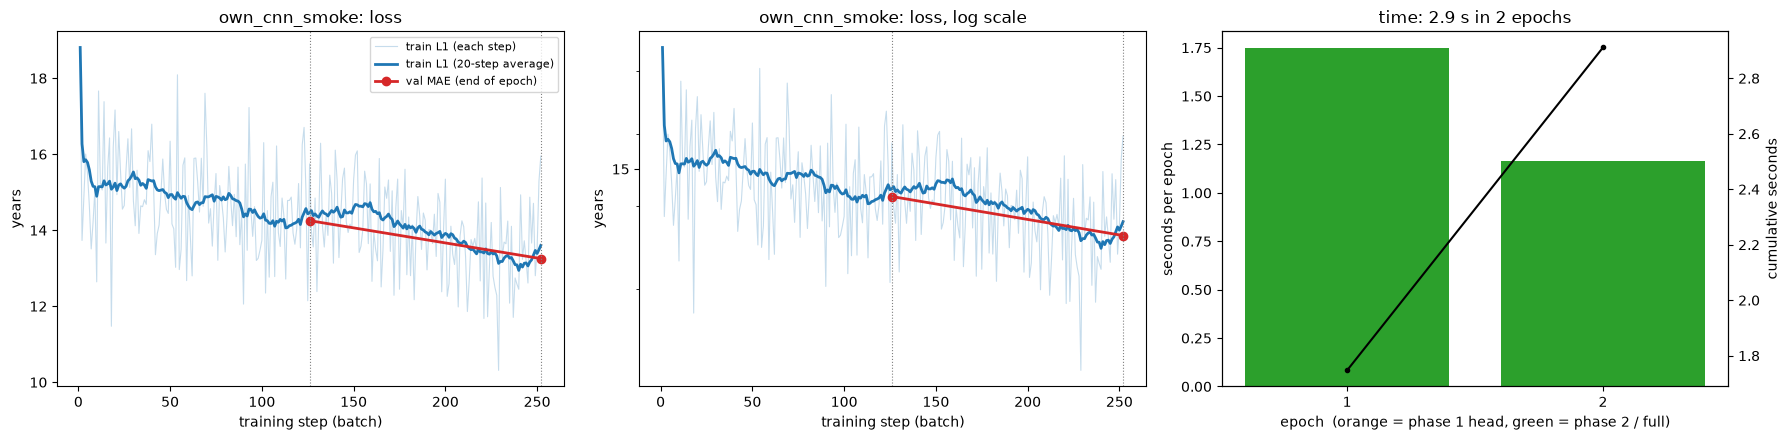

 epoch phase  train_l1  val_mae  lr_head  seconds
     1  full    14.772   14.252    0.000    1.747
     2  full    13.878   13.254    0.002    1.164

measured: 3.5 s, 0.295 Wh for 2 epochs (epoch 2: 1.16 s; epoch 1 includes cuDNN autotuning)
-> 40 epochs ≈ 0.8 min of training, ≈ 5.90 Wh (ResNet18 full: 2.7 s and 0.38 Wh per epoch)


In [10]:
SMOKE_RUN = "own_cnn_smoke"
if not already_logged(SMOKE_RUN):
    _ = train_model("own_cnn", SMOKE_RUN, strategy="full", kind="test", max_epochs=2, warmup_epochs=1,
                    lr_head=2e-3, lr_backbone=2e-3)
r = pd.read_csv(RUNS_CSV).set_index("run").loc[SMOKE_RUN]
h = pd.read_csv(TRAIN_LOG_DIR / f"{SMOKE_RUN}.csv")
print(h.round(3).to_string(index=False))
wh_epoch = 1000 * r.energy_kwh / r.epochs_run
print(f"\nmeasured: {r.duration_s:.1f} s, {1000 * r.energy_kwh:.3f} Wh for {r.epochs_run:.0f} epochs "
      f"(epoch 2: {h.seconds.iloc[-1]:.2f} s; epoch 1 includes cuDNN autotuning)")
print(f"-> 40 epochs ≈ {40 * h.seconds.iloc[-1] / 60:.1f} min of training, ≈ {40 * wh_epoch:.2f} Wh "
      f"(ResNet18 full: 2.7 s and 0.38 Wh per epoch)")

### 15.3 · Step 3: learning-rate check on a subset (a "small learning-rate search on a data subset", listed in the assignment)
Nothing is pretrained, so the standard-model learning rates do not carry over. Three values on a ×3 log grid:
**1e-3, 3e-3, 1e-2**, each for 10 epochs (1 warm-up + cosine) on the **same 4,000 random training images**
(the seeded generator picks the same subset every time), evaluated on the full val set. Cost: 3 × ~1/4 of a full run's images × 10 epochs.

Caveat (for the report): a short, small-data search tends to favour larger learning rates than the long full run would; we take the best
value and do not tune further. Choice rule, fixed before running: lowest best val MAE.

**Result: superseded.** All three rates stayed near the baseline; the diagnostic below (15.3.1) found an output-scale problem. These runs stay in the logs (they count for the project CO2); the search is repeated after the fix in 15.3.2.

   lr  best val MAE  best epoch  last val MAE  last train L1    Wh
0.001        13.390          10        13.390         13.555 0.405
0.003        12.928          10        12.928         13.070 0.355
0.010        12.725          10        12.725         12.911 0.355

-> chosen learning rate: 1e-02   (search cost 1.11 Wh)


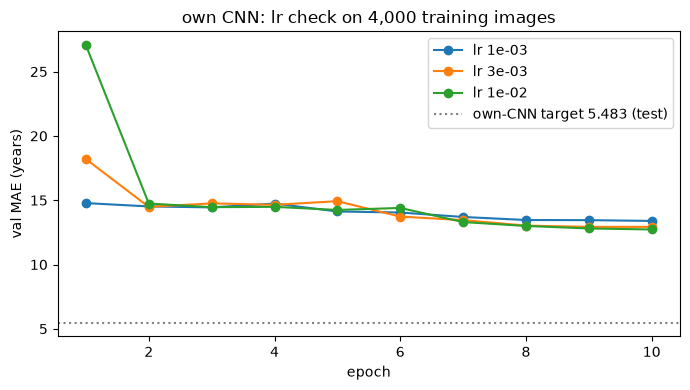

In [10]:
LRS = [1e-3, 3e-3, 1e-2]
search_hist = {}
for lr in LRS:
    run = f"own_cnn_lrsearch_{lr:.0e}"
    if not already_logged(run):
        print(f"=== {run} ===")
        train_model("own_cnn", run, strategy="full", kind="search", n_train=4000, max_epochs=10,
                    warmup_epochs=1, lr_head=lr, lr_backbone=lr)
    search_hist[lr] = pd.read_csv(TRAIN_LOG_DIR / f"{run}.csv")

runs_log = pd.read_csv(RUNS_CSV).set_index("run")
search = pd.DataFrame([{"lr": lr, "best val MAE": h.val_mae.min(), "best epoch": h.val_mae.idxmin() + 1,
                        "last val MAE": h.val_mae.iloc[-1], "last train L1": h.train_l1.iloc[-1],
                        "Wh": 1000 * runs_log.loc[f"own_cnn_lrsearch_{lr:.0e}"].energy_kwh}
                       for lr, h in search_hist.items()])
print(search.round(3).to_string(index=False))
BEST_LR = float(search.loc[search["best val MAE"].idxmin(), "lr"])
print(f"\n-> chosen learning rate: {BEST_LR:.0e}   (search cost {search.Wh.sum():.2f} Wh)")

fig, ax = plt.subplots(figsize=(7, 4))
for lr, h in search_hist.items():
    ax.plot(h.epoch, h.val_mae, "o-", label=f"lr {lr:.0e}")
ax.set_xlabel("epoch"); ax.set_ylabel("val MAE (years)"); ax.set_title("own CNN: lr check on 4,000 training images")
ax.axhline(5.483, color="grey", ls=":", label="own-CNN target 5.483 (test)"); ax.legend()
plt.tight_layout(); fig.savefig(FIG_DIR / "own_cnn_lr_search.png", dpi=110); plt.show()

#### 15.3.1 · Diagnostic: why is every learning rate still near the baseline after 310 steps?
Hypothesis: output scale. The head must map features of size ~1 to ages spread ±20 years around 33; Adam changes every weight by ≈ lr per step,
so head weights starting at 0 need many steps to become large enough. Check: spread (std) of the predictions vs the true ages, and the head weights.

In [11]:
if not already_logged("test_own_cnn_output_scale"):
    with track("test_own_cnn_output_scale", kind="test", gpu_ids=[0], notes="diagnostic: prediction spread of lr-search checkpoints on val"):
        rows = []
        for lr in LRS:
            m = build_model("own_cnn").to(DEV)
            m.load_state_dict(torch.load(CKPT_DIR / f"own_cnn_lrsearch_{lr:.0e}.pt"))
            p = predict(m, X_val)
            feats = torch.flatten(m.pool(m.stage4(m.stage3(m.stage2(m.stage1(m.stem(make_batch(X_val, torch.arange(512, device=DEV), False))))))), 1)
            rows.append({"lr": lr, "pred std": p.std().item(), "true age std": y_val.std().item(),
                         "corr(pred, age)": torch.corrcoef(torch.stack([p, y_val]))[0, 1].item(),
                         "|w_head|": m.fc.weight.norm().item(), "head bias": m.fc.bias.item(),
                         "feature mean": feats.mean().item(), "feature std": feats.std().item()})
    print(pd.DataFrame(rows).round(3).to_string(index=False))


[test_own_cnn_output_scale] ok | 2.1 s | 0.094 Wh (cpu 0.003, gpu 0.085, ram 0.006) | 0.044 g CO2eq
   lr  pred std  true age std  corr(pred, age)  |w_head|  head bias  feature mean  feature std
0.001     5.142        19.878            0.492     0.799     33.199         0.721        0.588
0.003     6.319        19.878            0.535     1.067     33.234         0.655        0.542
0.010     6.878        19.878            0.577     1.390     33.321         0.551        0.488


**Diagnostic result:** prediction std 5.1–6.9 years vs true 19.9; corr(pred, age) only 0.49–0.58; ‖w_head‖ 0.8–1.4. The predictions are squeezed
towards the mean: the head cannot grow fast enough (Adam: ≈ lr per step per weight).

**Fix (output scaling, standard for regression):** age = μ + σ · fc(features), μ = 33.23 and σ = train std (≈ 19.9), fixed buffers, not learned.
The head now predicts the age in standard deviations, so weights of size ~1 already span ±20 years. Loss unchanged (L1 in years).
Hand check: a feature vector with fc output +1.0 → 33.23 + 19.9 · 1.0 ≈ 53.1 years.

### 15.3.2 · Step 3 (repeated): learning-rate check with output scaling
Same grid, same 4,000 images, same 10 epochs, same choice rule (lowest best val MAE).

=== own_cnn_lrsearch2_1e-03 ===


epoch  1 [full]  train L1 14.894  |  val MAE 14.647  |  lr 3.2e-05  |   0.9 s


epoch  2 [full]  train L1 14.526  |  val MAE 14.425  |  lr 1.0e-03  |   0.3 s


epoch  3 [full]  train L1 14.118  |  val MAE 14.844  |  lr 9.7e-04  |   0.3 s


epoch  4 [full]  train L1 13.950  |  val MAE 13.617  |  lr 8.8e-04  |   0.3 s


epoch  5 [full]  train L1 13.400  |  val MAE 13.595  |  lr 7.5e-04  |   0.3 s


epoch  6 [full]  train L1 12.870  |  val MAE 12.455  |  lr 5.9e-04  |   0.3 s


epoch  7 [full]  train L1 12.324  |  val MAE 12.332  |  lr 4.1e-04  |   0.3 s


epoch  8 [full]  train L1 11.841  |  val MAE 11.869  |  lr 2.5e-04  |   0.3 s


epoch  9 [full]  train L1 11.617  |  val MAE 11.990  |  lr 1.2e-04  |   0.3 s


epoch 10 [full]  train L1 11.491  |  val MAE 11.874  |  lr 3.0e-05  |   0.3 s
[own_cnn_lrsearch2_1e-03] ok | 4.4 s | 0.396 Wh (cpu 0.007, gpu 0.377, ram 0.012) | 0.184 g CO2eq
best val MAE 11.869 at epoch 8  ->  checkpoints/own_cnn_lrsearch2_1e-03.pt  |  total 5.5 s


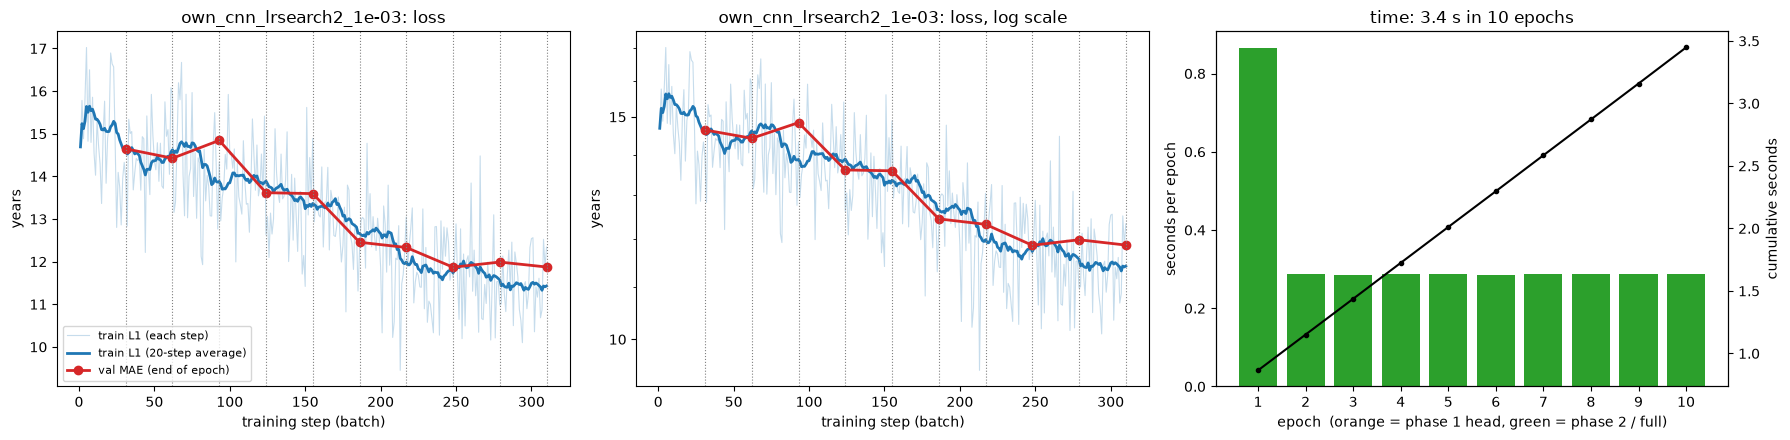

=== own_cnn_lrsearch2_3e-03 ===


epoch  1 [full]  train L1 14.813  |  val MAE 15.397  |  lr 9.7e-05  |   0.3 s


epoch  2 [full]  train L1 14.421  |  val MAE 14.358  |  lr 3.0e-03  |   0.3 s


epoch  3 [full]  train L1 13.796  |  val MAE 16.682  |  lr 2.9e-03  |   0.3 s


epoch  4 [full]  train L1 13.016  |  val MAE 13.963  |  lr 2.6e-03  |   0.3 s


epoch  5 [full]  train L1 12.511  |  val MAE 14.214  |  lr 2.3e-03  |   0.3 s


epoch  6 [full]  train L1 11.883  |  val MAE 12.134  |  lr 1.8e-03  |   0.3 s


epoch  7 [full]  train L1 11.356  |  val MAE 11.038  |  lr 1.2e-03  |   0.3 s


epoch  8 [full]  train L1 10.763  |  val MAE 12.674  |  lr 7.5e-04  |   0.3 s


epoch  9 [full]  train L1 10.463  |  val MAE 10.500  |  lr 3.5e-04  |   0.3 s


epoch 10 [full]  train L1 10.306  |  val MAE 10.416  |  lr 9.0e-05  |   0.3 s
[own_cnn_lrsearch2_3e-03] ok | 3.4 s | 0.355 Wh (cpu 0.005, gpu 0.341, ram 0.009) | 0.165 g CO2eq
best val MAE 10.416 at epoch 10  ->  checkpoints/own_cnn_lrsearch2_3e-03.pt  |  total 3.4 s


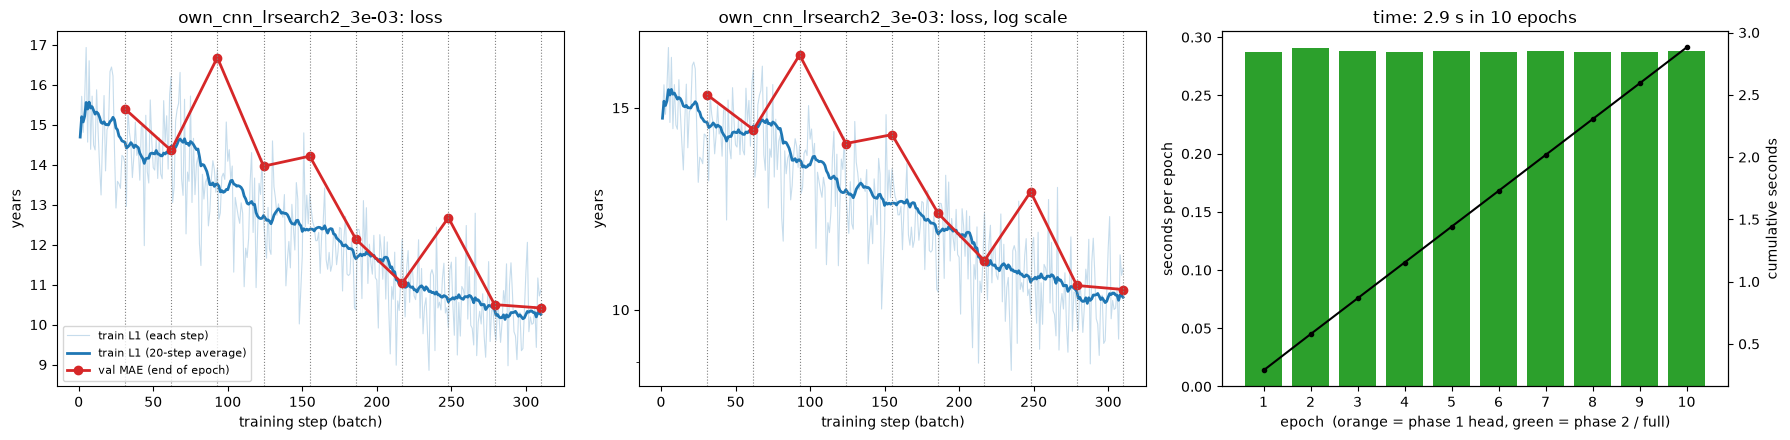

=== own_cnn_lrsearch2_1e-02 ===


epoch  1 [full]  train L1 14.846  |  val MAE 17.733  |  lr 3.2e-04  |   0.3 s


epoch  2 [full]  train L1 14.722  |  val MAE 14.595  |  lr 1.0e-02  |   0.3 s


epoch  3 [full]  train L1 14.248  |  val MAE 15.018  |  lr 9.7e-03  |   0.3 s


epoch  4 [full]  train L1 14.028  |  val MAE 13.816  |  lr 8.8e-03  |   0.3 s


epoch  5 [full]  train L1 13.209  |  val MAE 19.950  |  lr 7.5e-03  |   0.3 s


epoch  6 [full]  train L1 12.843  |  val MAE 12.039  |  lr 5.9e-03  |   0.3 s


epoch  7 [full]  train L1 11.618  |  val MAE 11.035  |  lr 4.1e-03  |   0.3 s


epoch  8 [full]  train L1 10.724  |  val MAE 11.205  |  lr 2.5e-03  |   0.3 s


epoch  9 [full]  train L1 10.048  |  val MAE 10.285  |  lr 1.2e-03  |   0.3 s


epoch 10 [full]  train L1  9.849  |  val MAE 10.014  |  lr 3.0e-04  |   0.3 s
[own_cnn_lrsearch2_1e-02] ok | 3.4 s | 0.356 Wh (cpu 0.005, gpu 0.341, ram 0.009) | 0.165 g CO2eq
best val MAE 10.014 at epoch 10  ->  checkpoints/own_cnn_lrsearch2_1e-02.pt  |  total 3.4 s


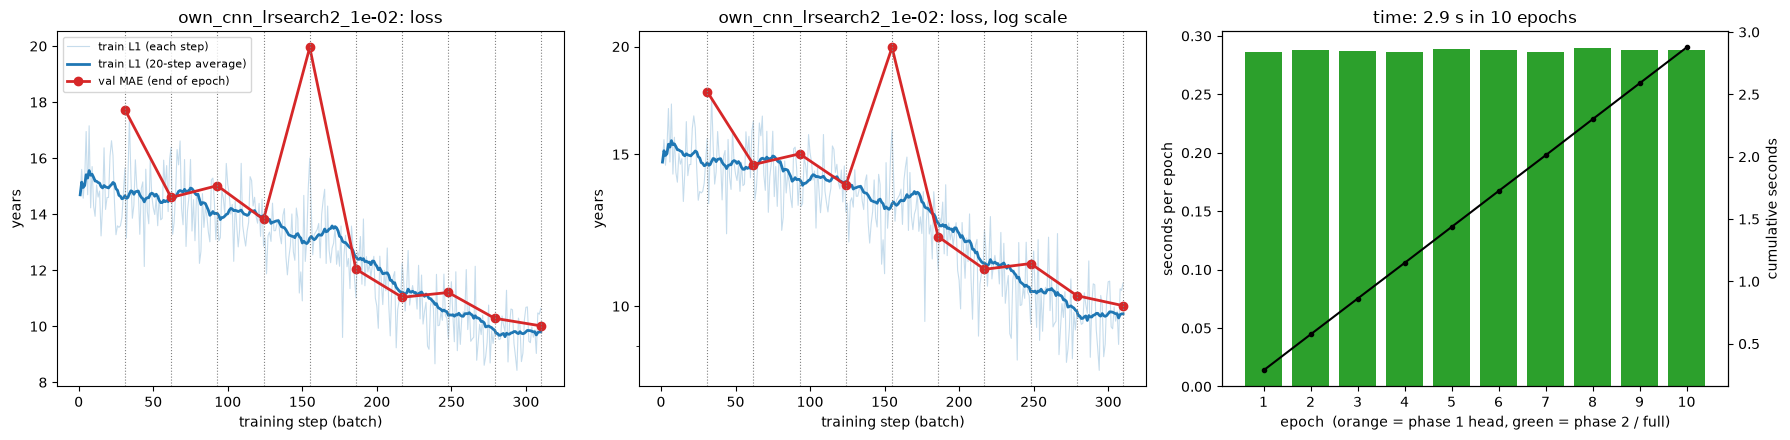

   lr  best val MAE  best epoch  last val MAE  last train L1    Wh
0.001        11.869           8        11.874         11.491 0.396
0.003        10.416          10        10.416         10.306 0.355
0.010        10.014          10        10.014          9.849 0.356

-> chosen learning rate: 1e-02   (this search 1.11 Wh; both searches + diagnostic are logged)


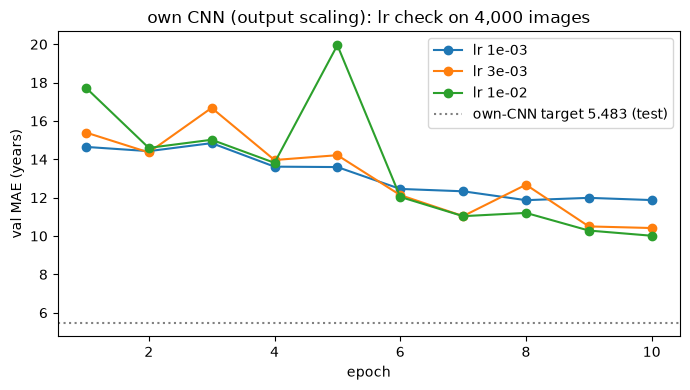

In [11]:
search_hist = {}
for lr in LRS:
    run = f"own_cnn_lrsearch2_{lr:.0e}"
    if not already_logged(run):
        print(f"=== {run} ===")
        train_model("own_cnn", run, strategy="full", kind="search", n_train=4000, max_epochs=10,
                    warmup_epochs=1, lr_head=lr, lr_backbone=lr)
    search_hist[lr] = pd.read_csv(TRAIN_LOG_DIR / f"{run}.csv")

runs_log = pd.read_csv(RUNS_CSV).set_index("run")
search = pd.DataFrame([{"lr": lr, "best val MAE": h.val_mae.min(), "best epoch": h.val_mae.idxmin() + 1,
                        "last val MAE": h.val_mae.iloc[-1], "last train L1": h.train_l1.iloc[-1],
                        "Wh": 1000 * runs_log.loc[f"own_cnn_lrsearch2_{lr:.0e}"].energy_kwh}
                       for lr, h in search_hist.items()])
print(search.round(3).to_string(index=False))
BEST_LR = float(search.loc[search["best val MAE"].idxmin(), "lr"])
print(f"\n-> chosen learning rate: {BEST_LR:.0e}   (this search {search.Wh.sum():.2f} Wh; both searches + diagnostic are logged)")

fig, ax = plt.subplots(figsize=(7, 4))
for lr, h in search_hist.items():
    ax.plot(h.epoch, h.val_mae, "o-", label=f"lr {lr:.0e}")
ax.set_xlabel("epoch"); ax.set_ylabel("val MAE (years)"); ax.set_title("own CNN (output scaling): lr check on 4,000 images")
ax.axhline(5.483, color="grey", ls=":", label="own-CNN target 5.483 (test)"); ax.legend()
plt.tight_layout(); fig.savefig(FIG_DIR / "own_cnn_lr_search2.png", dpi=110); plt.show()